# Tree-Type Neural Network: subject/context augmentation + a broad double-descent study

This notebook preserves the **CNN-root + recursive MLP correction-tree** architecture and evaluates both **Cats-vs-Dogs** and **CIFAR-10**. Inspired by `notebook1.ipynb`, it first tunes an intentionally underfit CNN root using a train-accuracy band and validation accuracy, then grows the correction tree toward **99.9% decoded training accuracy**. A richer augmentation policy varies geometry, lighting, color, blur, sensor noise, erasing, and low-frequency peripheral context. It compares that policy against no augmentation without assuming it improves test accuracy.

The experiments also include a dense width × seed sweep with long schedules and fine-grained epoch checkpoints under label noise, majority voting across independent tree models, bias²/variance versus sample count and epochs, and a local loss-landscape slice. The GPU double-descent study alone contains **368 root-training runs** (2 datasets × 2 augmentation policies × 23 widths × 4 seeds), before the clean/ensemble/bias–variance experiments.

The GPU profile is intentionally substantial and can take many hours. Runs are cached/resumable. Accuracy targets and double-descent conclusions are **measured outcomes, not guarantees**; do not change the report to call an inconclusive curve successful. Peripheral texture randomization is a background-robustness proxy, not true foreground segmentation, so it cannot guarantee the network focuses only on the subject.

**Numerical stability fix:** the paired McNemar test uses a log-domain binomial-tail calculation, so large discordant counts do not overflow when computing exact p-values.


In [2]:
import os, re, math, json, time, copy, random, warnings, itertools, heapq
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display

warnings.filterwarnings("ignore")
T0 = time.time()
SEED = 2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    DEVICE = "cuda"
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
if DEVICE == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))

OUT = Path("/kaggle/working/tree_nn_outputs" if Path("/kaggle/working").exists() else (Path.cwd() / "tree_nn_outputs")).resolve()
OUT.mkdir(parents=True, exist_ok=True)
DATA_DIR = OUT / "data_cache_v3_subject_aug"; DATA_DIR.mkdir(exist_ok=True)  # raw image arrays are unchanged; reuse prior data download cache
MODEL_DIR = OUT / "model_cache_v5_subject_aug"; MODEL_DIR.mkdir(exist_ok=True)

# Full profile reproduces the scale of the successful original notebook.
# Portable profiles stay smaller, but keep a reasonably dense width sweep.
CIFAR_SIZE = 32
BATCH_SIZE = 128 if DEVICE == "cuda" else 64
if DEVICE == "cuda":
    PROFILE = "full_gpu"
    CATS_DOGS_SIZE = 64
    DATA_SPLITS = {
        "cats_vs_dogs": (6800, 1200, 2000),
        "cifar10": (12750, 2250, 10000),
    }
    DD_N = {"cats_vs_dogs": 3000, "cifar10": 4000}
    DD_VAL_N = {"cats_vs_dogs": 1000, "cifar10": 1500}
    DD_TEST_N = {"cats_vs_dogs": 2000, "cifar10": 3000}
    DD_WIDTHS = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 16, 18, 20, 24, 28, 32, 40, 48, 64]
    DD_SEEDS = [0, 1, 2, 3]
    DD_EPOCHS = {"cats_vs_dogs": 160, "cifar10": 100}
    DD_EPOCH_CHECKPOINTS = {
        "cats_vs_dogs": list(range(10, 161, 10)),
        "cifar10": list(range(10, 101, 10)),
    }
    DD_NODE_BUDGET = {"cats_vs_dogs": 16, "cifar10": 40}
    DD_CHECK_EVERY = {"cats_vs_dogs": 2, "cifar10": 5}
    CLEAN_TREE_BUDGET = {"cats_vs_dogs": 150, "cifar10": 500}
    TREE_NODE_CAPS = {"cats_vs_dogs": 100, "cifar10": 60}
    ENSEMBLE_MEMBERS = 3
    ENSEMBLE_TREE_BUDGET = {"cats_vs_dogs": 100, "cifar10": 300}
    BIAS_EPOCHS = [1, 5, 12]
    BIAS_TEST_N = 500
    NODE_EP, NODE_BS = 60, 512
else:
    PROFILE = f"portable_{DEVICE}"
    CATS_DOGS_SIZE = 32
    DATA_SPLITS = {
        "cats_vs_dogs": (2000, 400, 600),
        "cifar10": (3000, 600, 1000),
    }
    DD_N = {"cats_vs_dogs": 800, "cifar10": 1200}
    DD_VAL_N = {"cats_vs_dogs": 300, "cifar10": 400}
    DD_TEST_N = {"cats_vs_dogs": 600, "cifar10": 1000}
    DD_WIDTHS = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 14, 16, 20, 24]
    DD_SEEDS = [0, 1, 2]
    DD_EPOCHS = {"cats_vs_dogs": 70, "cifar10": 50}
    DD_EPOCH_CHECKPOINTS = {
        "cats_vs_dogs": list(range(5, 71, 5)),
        "cifar10": list(range(5, 51, 5)),
    }
    DD_NODE_BUDGET = {"cats_vs_dogs": 8, "cifar10": 20}
    DD_CHECK_EVERY = {"cats_vs_dogs": 2, "cifar10": 3}
    CLEAN_TREE_BUDGET = {"cats_vs_dogs": 60, "cifar10": 180}
    TREE_NODE_CAPS = {"cats_vs_dogs": 40, "cifar10": 25}
    ENSEMBLE_MEMBERS = 3
    ENSEMBLE_TREE_BUDGET = {"cats_vs_dogs": 35, "cifar10": 100}
    BIAS_EPOCHS = [1, 4, 8]
    BIAS_TEST_N = 250
    NODE_EP, NODE_BS = 24, 128

# Reproduce the baseline's underfit-trunk strategy: select a trunk whose clean training
# accuracy is near 90–95%, with validation accuracy deciding among eligible candidates.
ROOT_TRAIN_BAND = (0.90, 0.95)
ROOT_TUNE_SEED = 404  # independent from the final three reported training seeds
if DEVICE == "cuda":
    ROOT_TUNE_EPOCHS = [5, 7, 9, 12, 16]
    ROOT_TUNE_RECIPES = [(48, 0.05, 5e-4), (64, 0.05, 5e-4), (64, 0.10, 1e-3)]
else:
    ROOT_TUNE_EPOCHS = [3, 5, 8]
    ROOT_TUNE_RECIPES = [(16, 0.05, 5e-4), (32, 0.05, 5e-4)]
if DEVICE == "cuda":
    TREE_TUNING_GRID = [("shared", 2, 16), ("varied", 2, 16), ("varied", 3, 32), ("varied", 1, 8), ("varied", 1, 4)]
else:
    TREE_TUNING_GRID = [("shared", 2, 8), ("varied", 2, 8), ("varied", 1, 4)]
REF_EPOCHS = 30 if DEVICE == "cuda" else 12  # longer-trained CNN reference, as in notebook1.ipynb

CLEAN_SEEDS = [101, 202, 303]
CIFAR_NAMES = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
NC = {'cats_vs_dogs': 2, 'cifar10': 10}
NAMES = {'cats_vs_dogs': ['cat','dog'], 'cifar10': CIFAR_NAMES}
MAX_DEPTH = 8
NODE_LR = 1e-2
TREE_NODE_CAP = max(TREE_NODE_CAPS.values())
NOISE_RATE = 0.20
INTERPOLATION_THRESHOLD = 0.999
ROOT_NOISY_STOP = 0.995
DD_CACHE_VERSION = (f"subject_aug_dd_v5_{PROFILE}_w{'-'.join(map(str, DD_WIDTHS))}_s{'-'.join(map(str, DD_SEEDS))}_"
                    f"epcd{DD_EPOCHS['cats_vs_dogs']}_c10{DD_EPOCHS['cifar10']}_"
                    f"ckcd{'-'.join(map(str, DD_EPOCH_CHECKPOINTS['cats_vs_dogs']))}_"
                    f"ckc10{'-'.join(map(str, DD_EPOCH_CHECKPOINTS['cifar10']))}_"
                    f"ncd{DD_N['cats_vs_dogs']}_c10{DD_N['cifar10']}_noise{int(100*NOISE_RATE)}")
BIAS_SIZES = [250, 500, 800]
BIAS_SEEDS = [0, 1, 2]
BIAS_TREE_BUDGET = 8
AUGMENTATION_MODES = [("no_augmentation", False), ("subject_preserving", "subject")]
print(f"Device={DEVICE} | profile={PROFILE} | outputs={OUT}")
print(f"Data splits (train/val/test): {DATA_SPLITS}; Cats-vs-Dogs image size={CATS_DOGS_SIZE}, CIFAR-10={CIFAR_SIZE}")
print(f"Final tree target: {INTERPOLATION_THRESHOLD:.1%} train accuracy | width sweep={len(DD_WIDTHS)} widths x {len(DD_SEEDS)} seeds x 2 augmentation modes; max epochs={DD_EPOCHS}")
print(f"Double-descent runs are checkpointed at epochs: {DD_EPOCH_CHECKPOINTS}")
print(f"Expected double-descent root fits: {2 * len(AUGMENTATION_MODES) * len(DD_WIDTHS) * len(DD_SEEDS)} across both datasets")
print(f"Root selection grid: {len(ROOT_TUNE_RECIPES)} recipes x {len(ROOT_TUNE_EPOCHS)} epoch values per dataset/augmentation")
print(f"Tree strategy/depth/node-width candidates: {len(TREE_TUNING_GRID)} per dataset/augmentation")


Device=cuda | profile=full_gpu | outputs=/kaggle/working/tree_nn_outputs
Data splits (train/val/test): {'cats_vs_dogs': (6800, 1200, 2000), 'cifar10': (12750, 2250, 10000)}; Cats-vs-Dogs image size=64, CIFAR-10=32
Final tree target: 99.9% train accuracy | width sweep=23 widths x 4 seeds x 2 augmentation modes; max epochs={'cats_vs_dogs': 160, 'cifar10': 100}
Double-descent runs are checkpointed at epochs: {'cats_vs_dogs': [10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150, 160], 'cifar10': [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]}
Expected double-descent root fits: 368 across both datasets
Root selection grid: 3 recipes x 5 epoch values per dataset/augmentation
Tree strategy/depth/node-width candidates: 5 per dataset/augmentation


## 1. Load the two real datasets

- **CIFAR-10:** uses its official training and test splits. The full GPU profile uses 12,750 train / 2,250 validation images and the official 10,000-image test set.
- **Cats-vs-Dogs:** prefers labelled local directories, then falls back to `microsoft/cats_vs_dogs` on Hugging Face. The full GPU profile uses 6,800 train / 1,200 validation / 2,000 held-out images and resizes to 64×64; portable runs use 32×32.
- Validation is used for experiment decisions and double-descent verdicts. Test performance is reported separately. The selected Cats-vs-Dogs split is random rather than an official benchmark split, so its result should be described accordingly.


In [3]:
def _resize_rgb(image, size=CIFAR_SIZE):
    if not isinstance(image, Image.Image):
        image = Image.fromarray(np.asarray(image))
    try:
        resample = Image.Resampling.BILINEAR
    except AttributeError:
        resample = Image.BILINEAR
    return np.asarray(image.convert("RGB").resize((size, size), resample), dtype=np.uint8)

def _to_tensor(images):
    arr = np.ascontiguousarray(images, dtype=np.uint8)
    return torch.from_numpy(arr).permute(0, 3, 1, 2).contiguous()

def _class_from_path(path):
    for part in reversed(path.parts):
        token = part.lower().strip()
        if token in {"cat", "cats"}: return 0
        if token in {"dog", "dogs"}: return 1
    name = path.name.lower()
    if re.match(r"cat[._-]", name): return 0
    if re.match(r"dog[._-]", name): return 1
    return None

def _load_local_catsdogs(n_total, seed, size=CATS_DOGS_SIZE):
    roots = [Path("/kaggle/input"), Path("./data"), Path("./datasets")]
    paths = set()
    for root in roots:
        if root.exists():
            try:
                for p in root.rglob("*"):
                    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}:
                        paths.add(p)
            except (PermissionError, OSError):
                pass
    cats, dogs = [], []
    for p in sorted(paths):
        label = _class_from_path(p)
        if label == 0: cats.append(p)
        elif label == 1: dogs.append(p)
    need_cat, need_dog = (n_total + 1)//2, n_total//2
    if len(cats) < need_cat or len(dogs) < need_dog:
        return None
    rng = np.random.RandomState(seed); rng.shuffle(cats); rng.shuffle(dogs)
    X, y = [], []
    for label, pool, goal in ((0, cats, need_cat), (1, dogs, need_dog)):
        got = 0
        for p in pool:
            try:
                X.append(_resize_rgb(Image.open(p), size=size)); y.append(label); got += 1
                if got >= goal: break
            except Exception:
                continue
        if got < goal: return None
    print(f"Cats-vs-Dogs source: local labelled image directories ({len(X)} images; {size}x{size})")
    return np.stack(X), np.asarray(y, dtype=np.int64)

def _load_hf_catsdogs(n_total, seed, size=CATS_DOGS_SIZE):
    try:
        from datasets import load_dataset
    except ImportError as e:
        raise RuntimeError("Cats-vs-Dogs data was not found locally. Install `datasets` (`pip install datasets`) to use the Hugging Face fallback.") from e
    token = os.environ.get("HF_TOKEN", "").strip() or None
    print(f"Cats-vs-Dogs source: Hugging Face microsoft/cats_vs_dogs (may download a large dataset; resize={size})")
    kwargs = {"split": "train", "download_mode": "reuse_dataset_if_exists"}
    if token: kwargs["token"] = token
    ds = load_dataset("microsoft/cats_vs_dogs", **kwargs).shuffle(seed=seed)
    need = [(n_total + 1)//2, n_total//2]
    X, y, counts = [], [], [0, 0]
    for i in range(len(ds)):
        try:
            ex = ds[i]
            label = int(ex.get("labels", ex.get("label")))
            if label not in (0, 1) or counts[label] >= need[label]: continue
            X.append(_resize_rgb(ex["image"], size=size)); y.append(label); counts[label] += 1
            if counts == need: break
        except Exception:
            continue
    if counts != need:
        raise RuntimeError(f"Could not load enough Cats-vs-Dogs images; loaded counts={counts}, expected={need}.")
    return np.stack(X), np.asarray(y, dtype=np.int64)

def _load_cifar_arrays(n_train_pool, n_test, seed):
    try:
        from torchvision.datasets import CIFAR10
        train_ds = CIFAR10(root=str(DATA_DIR / "torchvision"), train=True, download=True)
        test_ds = CIFAR10(root=str(DATA_DIR / "torchvision"), train=False, download=True)
        Xtr_all, ytr_all = train_ds.data, np.asarray(train_ds.targets, dtype=np.int64)
        Xte_all, yte_all = test_ds.data, np.asarray(test_ds.targets, dtype=np.int64)
    except Exception as exc:
        print("torchvision CIFAR-10 loader unavailable; trying Hugging Face fallback:", str(exc)[:180])
        try:
            from datasets import load_dataset
        except ImportError as e:
            raise RuntimeError("Could not load CIFAR-10 using torchvision or Hugging Face. Install torchvision, or install `datasets`.") from e
        ds = load_dataset("uoft-cs/cifar10")
        rng = np.random.RandomState(seed)
        def convert_split(split, n):
            order = rng.permutation(len(ds[split]))[:n]
            imgs, labs = [], []
            for i in order:
                row = ds[split][int(i)]
                imgs.append(_resize_rgb(row.get("img", row.get("image")), size=CIFAR_SIZE))
                labs.append(int(row["label"]))
            return np.stack(imgs), np.asarray(labs, dtype=np.int64)
        return (*convert_split("train", n_train_pool), *convert_split("test", n_test))
    rng = np.random.RandomState(seed)
    itrain = rng.permutation(len(Xtr_all))[:n_train_pool]
    itest = rng.permutation(len(Xte_all))[:n_test]
    return Xtr_all[itrain], ytr_all[itrain], Xte_all[itest], yte_all[itest]

def load_dataset_pack(name):
    ntr, nva, nte = DATA_SPLITS[name]
    size = CATS_DOGS_SIZE if name == "cats_vs_dogs" else CIFAR_SIZE
    cache = DATA_DIR / f"{name}_{ntr}_{nva}_{nte}_{size}_seed{SEED}.npz"
    if cache.exists():
        z = np.load(cache)
        arrays = {k: z[k] for k in z.files}
        print(f"Loaded cached {name} arrays ({size}x{size})")
    elif name == "cifar10":
        Xpool, ypool, Xtest, ytest = _load_cifar_arrays(ntr+nva, nte, SEED)
        arrays = dict(Xtr=Xpool[:ntr], ytr=ypool[:ntr],
                      Xva=Xpool[ntr:ntr+nva], yva=ypool[ntr:ntr+nva],
                      Xte=Xtest, yte=ytest)
        np.savez_compressed(cache, **arrays)
    else:
        n_total = ntr + nva + nte
        result = _load_local_catsdogs(n_total, SEED, size=size)
        if result is None: result = _load_hf_catsdogs(n_total, SEED, size=size)
        Xall, yall = result
        rng = np.random.RandomState(SEED); order = rng.permutation(len(yall))
        Xall, yall = Xall[order], yall[order]
        arrays = dict(Xtr=Xall[:ntr], ytr=yall[:ntr],
                      Xva=Xall[ntr:ntr+nva], yva=yall[ntr:ntr+nva],
                      Xte=Xall[ntr+nva:ntr+nva+nte], yte=yall[ntr+nva:ntr+nva+nte])
        np.savez_compressed(cache, **arrays)
    pack = {k: (_to_tensor(v) if k.startswith("X") else np.asarray(v, dtype=np.int64)) for k, v in arrays.items()}
    pack["nc"] = NC[name]; pack["names"] = NAMES[name]; pack["name"] = name
    print(f"{name}: train={len(pack['ytr'])}, val={len(pack['yva'])}, test={len(pack['yte'])}; image={size}x{size}; train class counts={np.bincount(pack['ytr'], minlength=pack['nc']).tolist()}")
    return pack

IM = {name: load_dataset_pack(name) for name in ("cats_vs_dogs", "cifar10")}
print("Both required real datasets are loaded and cached.")


Cats-vs-Dogs source: Hugging Face microsoft/cats_vs_dogs (may download a large dataset; resize=64)


README.md:   0%|          | 0.00/8.16k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  330MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  391MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/23410 [00:00<?, ? examples/s]

cats_vs_dogs: train=6800, val=1200, test=2000; image=64x64; train class counts=[3340, 3460]


100%|██████████| 170M/170M [02:19<00:00, 1.22MB/s] 


cifar10: train=12750, val=2250, test=10000; image=32x32; train class counts=[1285, 1331, 1262, 1227, 1282, 1301, 1238, 1292, 1258, 1274]
Both required real datasets are loaded and cached.


## 2. CNN trunk and multi-scale feature views

The original architecture is preserved: a three-stage CNN with a jointly trained root head. Shallow, middle, and deep pooled features are exposed to the recursively grown correction-tree nodes. On the full GPU profile, Cats-vs-Dogs uses a stride-2 first convolution at 64×64; CIFAR-10 stays at its native 32×32 resolution.


In [4]:
def prep(x):
    return (x.to(DEVICE).float() / 255.0 - 0.5) / 0.25

def augment(x, mode="subject"):
    """Randomized, label-preserving augmentation; x is standardized to roughly [-2, 2].

    `weak` is a flip + small translation control. `subject` adds mild zoom/rotation,
    brightness/contrast/saturation and white-balance jitter, occasional grayscale/blur,
    low-level sensor noise, small random erasing, and smooth low-frequency color texture
    added more strongly near image peripheries. The texture is a background/context
    randomization proxy, not segmentation; these transforms do not guarantee that the
    model attends only to the animal/object.
    """
    if mode in (None, False, "none"):
        return x
    x01 = (x * 0.25 + 0.5).clamp(0.0, 1.0)
    n, c, h, w = x01.shape
    device, dtype = x01.device, x01.dtype
    is_subject = mode not in ("weak", "light")

    flip = torch.where(torch.rand(n, device=device) < 0.5, -1.0, 1.0).to(dtype)
    if is_subject:
        angle = (torch.rand(n, device=device, dtype=dtype) * 2 - 1) * (10.0 * math.pi / 180.0)
        scale = 0.84 + 0.24 * torch.rand(n, device=device, dtype=dtype)
        tx = (torch.rand(n, device=device, dtype=dtype) * 2 - 1) * 0.10
        ty = (torch.rand(n, device=device, dtype=dtype) * 2 - 1) * 0.10
    else:
        angle = torch.zeros(n, device=device, dtype=dtype)
        scale = torch.ones(n, device=device, dtype=dtype)
        tx = (torch.rand(n, device=device, dtype=dtype) * 2 - 1) * 0.12
        ty = (torch.rand(n, device=device, dtype=dtype) * 2 - 1) * 0.12
    ca, sa = torch.cos(angle) * scale, torch.sin(angle) * scale
    theta = torch.zeros(n, 2, 3, device=device, dtype=dtype)
    theta[:, 0, 0] = ca * flip
    theta[:, 0, 1] = -sa * flip
    theta[:, 1, 0] = sa
    theta[:, 1, 1] = ca
    theta[:, 0, 2] = tx
    theta[:, 1, 2] = ty
    grid = F.affine_grid(theta, x01.shape, align_corners=False)
    x01 = F.grid_sample(x01, grid, mode="bilinear", padding_mode="reflection", align_corners=False)

    if is_subject:
        # Per-image brightness / contrast / saturation and mild channel-gain variation.
        brightness = 0.82 + 0.36 * torch.rand(n, 1, 1, 1, device=device, dtype=dtype)
        contrast = 0.78 + 0.44 * torch.rand(n, 1, 1, 1, device=device, dtype=dtype)
        saturation = 0.72 + 0.56 * torch.rand(n, 1, 1, 1, device=device, dtype=dtype)
        mean = x01.mean(dim=(2, 3), keepdim=True)
        x01 = (x01 - mean) * contrast + mean
        gray = 0.299 * x01[:, 0:1] + 0.587 * x01[:, 1:2] + 0.114 * x01[:, 2:3]
        x01 = gray + saturation * (x01 - gray)
        channel_gain = 0.94 + 0.12 * torch.rand(n, 3, 1, 1, device=device, dtype=dtype)
        x01 = (x01 * channel_gain) * brightness
        gamma = 0.90 + 0.20 * torch.rand(n, 1, 1, 1, device=device, dtype=dtype)
        x01 = x01.clamp(0, 1).pow(gamma)

        # A small fraction are grayscale or mildly blurred, but most retain full detail.
        gray_mask = (torch.rand(n, 1, 1, 1, device=device) < 0.04)
        gray = 0.299 * x01[:, 0:1] + 0.587 * x01[:, 1:2] + 0.114 * x01[:, 2:3]
        x01 = torch.where(gray_mask, gray.expand_as(x01), x01)
        blur_mask = (torch.rand(n, 1, 1, 1, device=device) < 0.06)
        blurred = F.avg_pool2d(F.pad(x01, (1, 1, 1, 1), mode="reflect"), kernel_size=3, stride=1)
        x01 = torch.where(blur_mask, blurred, x01)

        # Low-frequency peripheral context randomization. It changes slowly varying
        # edge/background appearance while preserving the central image region more often.
        # This is intentionally mild because the subject may extend to the edges.
        low_h, low_w = max(2, h//8), max(2, w//8)
        texture = torch.rand(n, 3, low_h, low_w, device=device, dtype=dtype) - 0.5
        texture = F.interpolate(texture, size=(h, w), mode="bilinear", align_corners=False)
        texture = texture / (texture.std(dim=(2, 3), keepdim=True) + 1e-4)
        coord_y = torch.linspace(-1, 1, h, device=device, dtype=dtype)
        coord_x = torch.linspace(-1, 1, w, device=device, dtype=dtype)
        gy, gx = torch.meshgrid(coord_y, coord_x, indexing="ij")
        edge_distance = torch.maximum(gx.abs(), gy.abs())
        edge_weight = ((edge_distance - 0.30) / 0.70).clamp(0, 1).pow(1.5)[None, None]
        texture_strength = 0.015 + 0.055 * torch.rand(n, 1, 1, 1, device=device, dtype=dtype)
        x01 = (x01 + texture * texture_strength * edge_weight).clamp(0, 1)

        # Small Cutout / Random Erasing to reduce dependence on one tiny background cue.
        erase_on = torch.rand(n, device=device) < 0.20
        rh = torch.randint(max(2, int(0.07*h)), max(3, int(0.18*h)+1), (n,), device=device)
        rw = torch.randint(max(2, int(0.07*w)), max(3, int(0.18*w)+1), (n,), device=device)
        cy = torch.randint(0, h, (n,), device=device); cx = torch.randint(0, w, (n,), device=device)
        top = (cy - rh//2).clamp(0, h); left = (cx - rw//2).clamp(0, w)
        yy = torch.arange(h, device=device)[None, :, None]
        xx = torch.arange(w, device=device)[None, None, :]
        erase = (erase_on[:, None, None] & (yy >= top[:, None, None]) & (yy < (top+rh).clamp(max=h)[:, None, None]) &
                 (xx >= left[:, None, None]) & (xx < (left+rw).clamp(max=w)[:, None, None]))
        x01 = torch.where(erase[:, None, :, :], torch.full_like(x01, 0.5), x01)
        x01 = (x01 + torch.randn_like(x01) * 0.012).clamp(0, 1)

    return (x01 - 0.5) / 0.25

class Trunk(nn.Module):
    """Original CNN root; pooled features at all stages are tree-node feature views."""
    def __init__(self, w, nc, res=32):
        super().__init__(); self.w = int(w)
        def block(i, o, stride=1):
            return nn.Sequential(nn.Conv2d(i, o, 3, stride, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
        self.s1 = nn.Sequential(block(3, w, 2 if res >= 64 else 1), block(w, w), nn.MaxPool2d(2))
        self.s2 = nn.Sequential(block(w, 2*w), block(2*w, 2*w), nn.MaxPool2d(2))
        self.s3 = nn.Sequential(block(2*w, 4*w), block(4*w, 4*w))
        self.head = nn.Linear(4*w, nc)
    def feats(self, x):
        a = self.s1(x); b = self.s2(a); c = self.s3(b)
        return [a.mean((2,3)), b.mean((2,3)), c.mean((2,3))]
    def forward(self, x):
        return self.head(self.feats(x)[2])

def _safe_load_state(path, model):
    try:
        state = torch.load(path, map_location=DEVICE, weights_only=True)
    except TypeError:
        state = torch.load(path, map_location=DEVICE)
    model.load_state_dict(state)
    return model.eval()

def train_trunk(X, y, nc, w, ep, lr, wd, seed, aug=False, opt="sgd", bs=None,
                cache_key=None, checkpoints=None, stop_train_acc=None, min_stop_epoch=10):
    """Train the CNN root; optional epoch snapshots support temporal diagnostics."""
    bs = bs or BATCH_SIZE
    checkpoints = set(checkpoints or [])
    cache_path = MODEL_DIR / f"{cache_key}.pt" if cache_key and not checkpoints else None
    model = Trunk(w, nc, X.shape[-1]).to(DEVICE)
    if cache_path is not None and cache_path.exists():
        print(f"  model cache hit: {cache_path.name}")
        return _safe_load_state(cache_path, model), {}
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    model = Trunk(w, nc, X.shape[-1]).to(DEVICE)
    order_generator = torch.Generator(device="cpu")
    order_generator.manual_seed(int(seed) + 4517)
    y_cpu = torch.as_tensor(np.asarray(y), dtype=torch.long)
    steps_per_epoch = math.ceil(len(X) / bs)
    if opt == "sgd":
        optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=wd, nesterov=True)
        total_steps = max(2, ep*steps_per_epoch)
        scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, lr, total_steps=total_steps,
                                                        pct_start=0.25 if total_steps >= 10 else 0.75)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
        scheduler = None
    snapshots = {}
    aug_mode = ("subject" if aug is True else aug)
    for epoch in range(1, ep + 1):
        model.train(); order = torch.randperm(len(X), generator=order_generator)
        for start in range(0, len(X), bs):
            ids = order[start:start+bs]
            xb = prep(X[ids]); yb = y_cpu[ids].to(DEVICE)
            if aug: xb = augment(xb, mode=aug_mode)
            logits = model(xb); loss = F.cross_entropy(logits, yb)
            optimizer.zero_grad(set_to_none=True); loss.backward(); optimizer.step()
            if scheduler is not None: scheduler.step()
        if epoch in checkpoints:
            snapshots[epoch] = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if stop_train_acc is not None and epoch >= min_stop_epoch:
            with torch.no_grad():
                train_logits, _ = extract(model, X)
                fit_acc = float((train_logits.argmax(1).numpy() == np.asarray(y)).mean())
            if fit_acc >= stop_train_acc:
                print(f"  stopped at epoch {epoch}: raw training accuracy={fit_acc:.3f} reached {stop_train_acc:.3f}")
                break
    model.eval()
    if cache_path is not None:
        torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, cache_path)
    return model, snapshots

@torch.no_grad()
def extract(model, X, bs=512):
    logits_all, feats_all = [], []
    model.eval()
    for start in range(0, len(X), bs):
        f = model.feats(prep(X[start:start+bs]))
        logits_all.append(model.head(f[2]).float().cpu())
        feats_all.append(torch.cat(f, dim=1).float().cpu())
    return torch.cat(logits_all), torch.cat(feats_all)

def root_scores(logits, nc):
    """Binary log-odds or multiclass one-vs-rest log-odds used by the original tree roots."""
    if nc == 2:
        return (logits[:, 1] - logits[:, 0])[:, None]
    return torch.stack([logits[:, k] - torch.logsumexp(torch.cat([logits[:, :k], logits[:, k+1:]], dim=1), dim=1)
                        for k in range(nc)], dim=1)

def make_D(model, X3, y3, nc, names):
    Xall = torch.cat(X3)
    logits, features = extract(model, Xall)
    ntr, nva, nte = map(len, X3)
    mu = features[:ntr].mean(0); sd = features[:ntr].std(0) + 1e-6
    w = model.w
    return dict(ntr=ntr, nva=nva, nte=nte, ntot=len(Xall),
                ytr=np.asarray(y3[0]), yva=np.asarray(y3[1]), yte=np.asarray(y3[2]),
                nc=nc, names=names, logits=logits, R=root_scores(logits, nc).numpy(),
                F=((features - mu) / sd).clamp(-6, 6), mu=mu, sd=sd,
                sl=dict(shallow=slice(0,w), mid=slice(w,3*w), deep=slice(3*w,7*w)),
                trunk=model, tparams=sum(p.numel() for p in model.parameters()), V={})

def take(D, Fz, name):
    parts = []
    for p in name.split("+"):
        parts += ["shallow", "mid", "deep"] if p == "all" else [p]
    return torch.cat([Fz[:, D["sl"][p]] for p in dict.fromkeys(parts)], dim=1)

def view(D, name):
    if name not in D["V"]: D["V"][name] = take(D, D["F"], name).contiguous()
    return D["V"][name]

def cnn_acc(D, ycls=None):
    pred = D["logits"].argmax(1).numpy(); n, v = D["ntr"], D["nva"]
    y_train = D["ytr"] if ycls is None else np.asarray(ycls)
    return dict(tr=float((pred[:n] == y_train).mean()),
                va=float((pred[n:n+v] == D["yva"]).mean()) if v else float("nan"),
                te=float((pred[n+v:] == D["yte"]).mean()))
print("Original CNN root and multi-scale feature views are ready; subject-preserving augmentation is active when selected.")


Original CNN root and multi-scale feature views are ready; subject-preserving augmentation is active when selected.


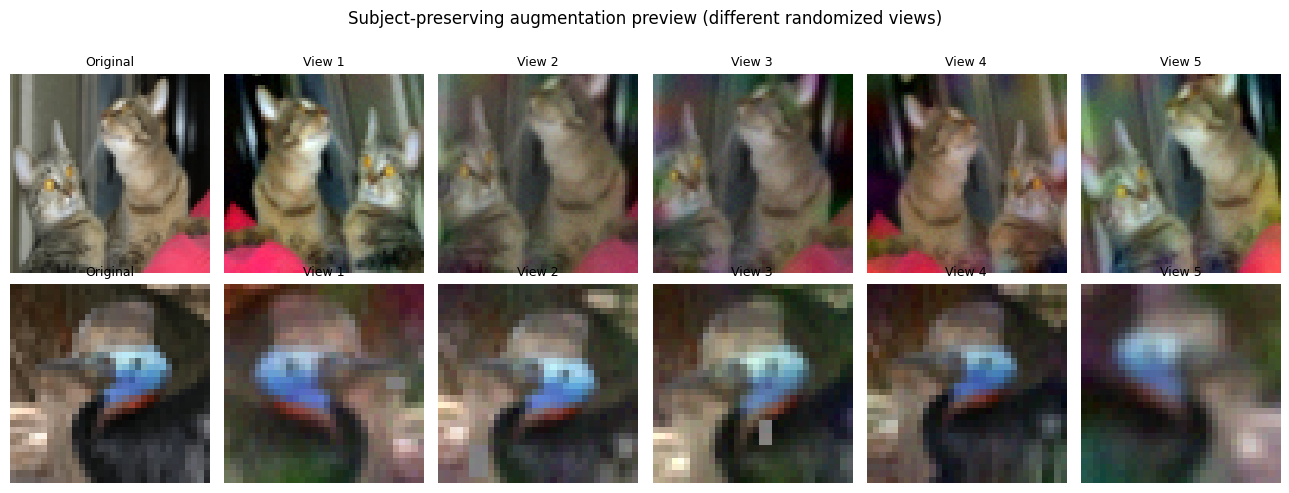

In [5]:
# Preview one original image and several independently randomized augmented views.
# This is an inspection aid, not an experiment metric.
fig, axes = plt.subplots(2, 6, figsize=(13, 4.8))
for row, ds in enumerate(IM.keys()):
    pack = IM[ds]
    idx = 0
    x_raw = pack["Xtr"][idx:idx+1]
    x = prep(x_raw)
    variants = [x] + [augment(x, mode="subject") for _ in range(5)]
    for col, view_tensor in enumerate(variants):
        image = (view_tensor[0].detach().cpu() * 0.25 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy()
        axes[row, col].imshow(image)
        axes[row, col].axis("off")
        axes[row, col].set_title("Original" if col == 0 else f"View {col}", fontsize=9)
    axes[row, 0].set_ylabel(f"{ds}\nlabel={int(pack['ytr'][idx])}", fontsize=10)
plt.suptitle("Subject-preserving augmentation preview (different randomized views)", y=1.02)
plt.tight_layout()
plt.show()

## 3. Recursive correction-tree algorithm

The original correction-tree logic is retained: per-class root scores, MLP child nodes trained on their class-specific don't-care sets, and non-negative correction weights. The final clean-label experiment grows the tree until it reaches the 99.9% decoded training-accuracy target or exhausts its configured budget. The report distinguishes a reached target from a budget/cap failure.


In [6]:
def get_layer_widths(L, base, peak=2):
    if L <= 0: return []
    if L == 1: return [int(base)]
    k = L//2; span = max(k, L-1-k)
    return [max(1, int(round(base*(1+(peak-1)*(1-abs(i-k)/span))))) for i in range(L)]

def make_mlp(din, widths):
    layers, d = [], din
    for w in widths:
        layers += [nn.Linear(d, w), nn.ReLU()]; d = w
    return nn.Sequential(*layers, nn.Linear(d, 1))

def const_node(din, val):
    m = nn.Linear(din, 1); nn.init.zeros_(m.weight); nn.init.constant_(m.bias, val); m.is_const = True
    return m

def train_node(X, t, widths, seed, max_ep, lr, bs, min_steps=300):
    din = X.shape[1]; torch.manual_seed(seed)
    if len(t) == 0 or float(t.min()) == float(t.max()):
        p = 0.5 if len(t) == 0 else (0.98 if float(t[0]) > 0.5 else 0.02)
        return const_node(din, float(np.log(p/(1-p))))
    model = make_mlp(din, widths); model.is_const = False
    n = len(X); spe = math.ceil(n/bs); ep = min(400, max(max_ep, math.ceil(min_steps/spe)))  # small hard sets get up to 300+ updates, as in notebook1.ipynb
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(1, ep*spe))
    pos = max(1.0, float((t < 0.5).sum()) / max(1.0, float((t > 0.5).sum())))
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(min(20.0, pos)))
    for epoch in range(ep):
        order = torch.randperm(n)
        for start in range(0, n, bs):
            ids = order[start:start+bs]
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(X[ids]).squeeze(1), t[ids]); loss.backward(); optimizer.step(); scheduler.step()
        if epoch % 3 == 2 or epoch == ep-1:
            with torch.no_grad(): out = model(X).squeeze(1)
            if not torch.isfinite(out).all(): return const_node(din, 0.0)
            if ((out > 0) == (t > 0.5)).all(): break
    return model

def fit_w(base, t, out, sign):
    bad = ((t == 1) & (out == 1) & (base <= 0)) if sign > 0 else ((t == 0) & (out == 1) & (base > 0))
    if not bad.any(): return 0.0
    candidates = np.unique((-base[bad] if sign > 0 else base[bad]) * 1.01 + 1e-3)
    if len(candidates) > 24: candidates = np.quantile(candidates, np.linspace(0, 1, 24))
    candidates = np.concatenate([[0.0], candidates])
    pred = (base[None, :] + sign*candidates[:, None]*out[None, :]) > 0
    return float(candidates[int(np.argmax((pred == (t[None, :] > 0.5)).mean(1)))])

def make_strategy(name):
    def strategy(role, depth, nid):
        if name == "shared": return "all"
        if depth == 1: return "mid+deep" if role == "A" else "deep"
        return ["shallow+mid", "mid+deep", "deep"][nid % 3]
    return strategy

class Tree:
    def __init__(self, E, k):
        self.E, self.k, self.y = E, k, E.T[:, k]
        self.nodes, self.heap, self.cnt, self.H, self.cache, self._w = [], [], itertools.count(), [], {}, {}
        self.push(E.ntr, dict(parent=-1, role="root", depth=0, idx=np.arange(E.ntr), t=self.y))
    def push(self, priority, task): heapq.heappush(self.heap, (-priority, next(self.cnt), task))
    def top(self): return -self.heap[0][0] if self.heap else -1
    def grow_one(self):
        _, _, task = heapq.heappop(self.heap); E = self.E; nid = len(self.nodes); idx, t = task["idx"], task["t"]
        if task["role"] == "root": model, h, view_name = None, E.R[:, self.k], "trunk-head"
        else:
            view_name = E.strategy(task["role"], task["depth"], nid); X_view = E.view(view_name)
            model = train_node(X_view[idx], torch.from_numpy(t).float(), E.widths,
                               E.seed*100003 + self.k*1009 + nid, E.max_ep, E.lr, E.bs)
            with torch.no_grad(): h = model(X_view).squeeze(1).numpy()
        self.H.append(h); z = h[idx]
        node = dict(id=nid, parent=task["parent"], role=task["role"], depth=task["depth"], view=view_name,
                    idx=idx, t=t, model=model, A=-1, B=-1,
                    np=0 if model is None else (1 if getattr(model, "is_const", False) else sum(p.numel() for p in model.parameters())))
        self.nodes.append(node)
        if task["parent"] >= 0: self.nodes[task["parent"]][task["role"]] = nid
        if task["depth"] < E.max_depth:
            pos = z > 0; fn = (t == 1) & (~pos); fp = (t == 0) & pos
            if fn.any():
                keep = ~((t == 1) & pos)
                self.push(int(fn.sum()), dict(parent=nid, role="A", depth=task["depth"]+1,
                                               idx=idx[keep], t=fn[keep].astype(np.float32)))
            if fp.any():
                keep = ~((t == 0) & (~pos))
                self.push(int(fp.sum()), dict(parent=nid, role="B", depth=task["depth"]+1,
                                               idx=idx[keep], t=fp[keep].astype(np.float32)))
    def _combine(self, N, active=None):
        scores = [None]*N
        for i in range(N-1, -1, -1):
            if active is not None and not active[i]: continue
            node = self.nodes[i]; zi = self.H[i].copy()
            for role, sign in (("A", 1), ("B", -1)):
                child = node[role]
                if 0 <= child < N and (active is None or active[child]):
                    out = (scores[child] > 0).astype(np.float32)
                    weight = fit_w(zi[node["idx"]], node["t"], out[node["idx"]], sign)
                    if active is None: self._w[(N, i, role)] = weight
                    zi = zi + sign*weight*out
            scores[i] = zi
        return scores[0]
    def scores_active(self, active): return self._combine(len(self.nodes), np.asarray(active, bool))
    def scores(self, N=None):
        N = len(self.nodes) if N is None else min(N, len(self.nodes))
        if N not in self.cache: self.cache[N] = self._combine(N)
        return self.cache[N]
    def stats(self):
        internal = sum(1 for node in self.nodes if 0 <= node["A"] < len(self.nodes) or 0 <= node["B"] < len(self.nodes))
        return dict(nodes=len(self.nodes), internal=internal, leaves=len(self.nodes)-internal,
                    depth=max(node["depth"] for node in self.nodes)+1,
                    params=sum(node["np"] for node in self.nodes)+2*internal)

class TreeEnsemble:
    """The original multiclass tree-type predictor: one recursively grown tree per class."""
    def __init__(self, D, ycls, widths, strategy, seed=0, max_nodes=20, max_depth=MAX_DEPTH,
                 max_ep=NODE_EP, lr=NODE_LR, bs=NODE_BS):
        self.D, self.ntr, self.ycls = D, D["ntr"], np.asarray(ycls)
        self.widths, self.strategy, self.seed = widths, strategy, seed
        self.max_nodes, self.max_depth, self.max_ep, self.lr, self.bs = max_nodes, max_depth, max_ep, lr, bs
        self.R = D["R"]
        self.T = ((self.ycls == 1)[:, None] if D["nc"] == 2 else (self.ycls[:, None] == np.arange(D["nc"])[None, :])).astype(np.float32)
        self.trees = [Tree(self, k) for k in range(self.T.shape[1])]
    def view(self, name): return view(self.D, name)
    def Z(self): return np.stack([tree.scores() for tree in self.trees], axis=1)
    def pred(self, Z): return (Z[:, 0] > 0).astype(int) if Z.shape[1] == 1 else Z.argmax(1)
    def acc(self, Z=None):
        P = self.pred(self.Z() if Z is None else Z); D = self.D; n, v = self.ntr, D["nva"]
        return dict(tr=float((P[:n] == self.ycls).mean()),
                    clean=float((P[:n] == D["ytr"]).mean()),
                    va=float((P[n:n+v] == D["yva"]).mean()) if v else float("nan"),
                    te=float((P[n+v:] == D["yte"]).mean()))
    def summary(self, target):
        acc = self.acc(); stats = [tree.stats() for tree in self.trees]
        return dict(train_acc=acc["tr"], clean_train_acc=acc["clean"], val_acc=acc["va"], test_acc=acc["te"],
                    nodes=sum(x["nodes"] for x in stats), internal=sum(x["internal"] for x in stats),
                    leaves=sum(x["leaves"] for x in stats), tree_depth=max(x["depth"] for x in stats),
                    tree_params=sum(x["params"] for x in stats), total_params=sum(x["params"] for x in stats)+self.D["tparams"],
                    target=target, reached=(acc["tr"] >= target) if target is not None else None)
    def fit(self, target, max_total, check_every=2):
        for tree in self.trees: tree.grow_one()
        total = 0; acc = self.acc(); self.hist = [(0, acc["tr"], acc["va"], acc["te"])]; reason = None
        while True:
            if target is not None and acc["tr"] >= target: reason = "target reached"; break
            candidates = [tree for tree in self.trees if tree.heap and len(tree.nodes) < self.max_nodes]
            if not candidates: reason = "all correction tasks resolved" if all(not tree.heap for tree in self.trees) else "per-tree node cap reached"; break
            if total >= max_total: reason = "node budget exhausted"; break
            max(candidates, key=lambda tree: tree.top()).grow_one(); total += 1
            if total % check_every == 0: acc = self.acc(); self.hist.append((total, acc["tr"], acc["va"], acc["te"]))
        acc = self.acc(); result = self.summary(target); result["reason"] = reason; result["grown_nodes"] = total; self.snap = result
        return result

def add_noise(y, n_classes, rate, rng):
    out = np.asarray(y).copy(); flip = rng.rand(len(out)) < rate
    if flip.any(): out[flip] = (out[flip] + rng.randint(1, n_classes, flip.sum())) % n_classes
    return out

def run_tree(D, ycls, strategy="varied", depth=2, base_width=8, target=0.99,
             max_total=16, max_nodes=TREE_NODE_CAP, check_every=2, seed=0, epochs=NODE_EP):
    model = TreeEnsemble(D, ycls, get_layer_widths(depth, base_width), make_strategy(strategy),
                         seed=seed, max_nodes=max_nodes, max_ep=epochs, lr=NODE_LR, bs=NODE_BS)
    result = model.fit(target, max_total, check_every)
    return result, model

print("Recursive correction-tree definitions loaded.")

Recursive correction-tree definitions loaded.


## 4. Requirement 1 — rich augmentation, high train accuracy, and double descent

Two clean-label conditions are compared over three final seeds: **no augmentation** and **subject-preserving/context-randomized augmentation** (flip, mild affine/zoom, varied lighting and color, occasional grayscale/blur, low sensor noise, small random erasing, and low-frequency peripheral context randomization). Each condition first selects an underfit CNN recipe from the validation-only width/learning-rate/weight-decay/epoch grid, preferring roots with 90–95% clean training accuracy and highest validation accuracy. It then tunes tree strategy/depth/node width on validation, preferring target-reaching trees and choosing the smallest within one standard error of best validation accuracy. Both selected recipes are fixed across three final paired seeds. A longer-trained CNN-only reference is also reported, following `notebook1.ipynb`. The tree targets 99.9% decoded training accuracy; test metrics are reported without being used for model selection.

For double descent, 20% of training labels are corrupted while validation and test labels remain clean. The capacity sweep uses a dense width grid around the interpolation region, multiple seeds, a long fixed epoch schedule, and dense saved epoch checkpoints (every 10 epochs in the full GPU profile and every 5 epochs in the portable profile). The primary verdict uses **validation error**, requires every seed to hit the noisy-label interpolation threshold, and checks whether the rise-and-fall pattern is consistent across seeds. Test accuracy is reported but does not decide the verdict.



Root recipe search: cats_vs_dogs | no_augmentation
  w=48 lr=0.05 wd=0.0005 ep= 5: train=0.888 val=0.829
  w=48 lr=0.05 wd=0.0005 ep= 7: train=0.930 val=0.847
  w=48 lr=0.05 wd=0.0005 ep= 9: train=0.976 val=0.868
  w=48 lr=0.05 wd=0.0005 ep=12: train=0.998 val=0.861
  w=48 lr=0.05 wd=0.0005 ep=16: train=0.999 val=0.873
  w=64 lr=0.05 wd=0.0005 ep= 5: train=0.890 val=0.843
  w=64 lr=0.05 wd=0.0005 ep= 7: train=0.944 val=0.864
  w=64 lr=0.05 wd=0.0005 ep= 9: train=0.975 val=0.854
  w=64 lr=0.05 wd=0.0005 ep=12: train=0.998 val=0.874
  w=64 lr=0.05 wd=0.0005 ep=16: train=1.000 val=0.871
  w=64 lr=0.1 wd=0.001 ep= 5: train=0.875 val=0.838
  w=64 lr=0.1 wd=0.001 ep= 7: train=0.928 val=0.860
  w=64 lr=0.1 wd=0.001 ep= 9: train=0.974 val=0.873
  w=64 lr=0.1 wd=0.001 ep=12: train=0.998 val=0.881
  w=64 lr=0.1 wd=0.001 ep=16: train=1.000 val=0.880
SELECTED cats_vs_dogs / no_augmentation: width=64, lr=0.05, wd=0.0005, epochs=7; train=0.944, validation=0.864 (best validation accuracy among roots

,dataset,augmentation,width,lr,wd,epochs,root_params,train_acc,val_acc,in_train_band
13,cats_vs_dogs,no_augmentation,64,0.10,0.0010,12,1146818,0.9975,0.8808,False
14,cats_vs_dogs,no_augmentation,64,0.10,0.0010,16,1146818,1.0000,0.8800,False
8,cats_vs_dogs,no_augmentation,64,0.05,0.0005,12,1146818,0.9982,0.8742,False
4,cats_vs_dogs,no_augmentation,48,0.05,0.0005,16,645842,0.9994,0.8733,False
12,cats_vs_dogs,no_augmentation,64,0.10,0.0010,9,1146818,0.9741,0.8725,False
9,cats_vs_dogs,no_augmentation,64,0.05,0.0005,16,1146818,0.9999,0.8708,False
2,cats_vs_dogs,no_augmentation,48,0.05,0.0005,9,645842,0.9765,0.8675,False
6,cats_vs_dogs,no_augmentation,64,0.05,0.0005,7,1146818,0.9444,0.8642,True
3,cats_vs_dogs,no_augmentation,48,0.05,0.0005,12,645842,0.9978,0.8608,False
11,cats_vs_dogs,no_augmentation,64,0.10,0.0010,7,1146818,0.9278,0.8600,True


  model cache hit: root_tune_v5_full_gpu_cats_vs_dogs_no_augmentation_w64_lr0.05_wd0.0005_ep7_seed404.pt

Tree recipe search: cats_vs_dogs | no_augmentation
  shared depth=2 node_width=16: train=1.0000 val=0.824 nodes=5 params=1177868 reached=True (target reached)
  varied depth=2 node_width=16: train=1.0000 val=0.834 nodes=5 params=1168652 reached=True (target reached)
  varied depth=3 node_width=32: train=1.0000 val=0.851 nodes=5 params=1202764 reached=True (target reached)
  varied depth=1 node_width= 8: train=0.9999 val=0.829 nodes=7 params=1160754 reached=True (target reached)
  varied depth=1 node_width= 4: train=0.9994 val=0.834 nodes=11 params=1158696 reached=True (target reached)
SELECTED TREE cats_vs_dogs/no_augmentation: {'strategy': 'varied', 'depth': 3, 'base_width': 32, 'selection_val_acc': 0.8508333333333333, 'selection_train_acc': 1.0, 'selection_reached': True, 'selection_nodes': 5, 'selection_params': 1202764, 'selection_rule': 'target-reaching candidates; smallest mo

,dataset,augmentation,strategy,depth,base_width,train_acc,val_acc,nodes,total_params,reached_target,reason
2,cats_vs_dogs,no_augmentation,varied,3,32,1.0000,0.8508,5,1202764,True,target reached
1,cats_vs_dogs,no_augmentation,varied,2,16,1.0000,0.8342,5,1168652,True,target reached
4,cats_vs_dogs,no_augmentation,varied,1,4,0.9994,0.8342,11,1158696,True,target reached
3,cats_vs_dogs,no_augmentation,varied,1,8,0.9999,0.8292,7,1160754,True,target reached
0,cats_vs_dogs,no_augmentation,shared,2,16,1.0000,0.8242,5,1177868,True,target reached
8,cats_vs_dogs,subject_preserving,varied,1,8,0.9996,0.8808,7,1160752,True,target reached
5,cats_vs_dogs,subject_preserving,shared,2,16,1.0000,0.8708,5,1177868,True,target reached
7,cats_vs_dogs,subject_preserving,varied,3,32,1.0000,0.8683,5,1202764,True,target reached
9,cats_vs_dogs,subject_preserving,varied,1,4,0.9994,0.8683,17,1165158,True,target reached
6,cats_vs_dogs,subject_preserving,varied,2,16,1.0000,0.8658,5,1168652,True,target reached



Clean-label experiment: cats_vs_dogs | no_augmentation | seed=101 | selected root={'width': 64, 'lr': 0.05, 'wd': 0.0005, 'epochs': 7, 'selection_train_acc': 0.9444117647058824, 'selection_val_acc': 0.8641666666666666, 'selection_rule': 'best validation accuracy among roots in the 90–95% train band'}
  underfit CNN train/test=0.952/0.844; long-trained CNN reference train/test=1.000/0.865; CNN+tree train/val/test=0.9993/0.845/0.838; tree=varied/L3/w32, nodes=3 (target reached)

Clean-label experiment: cats_vs_dogs | subject_preserving | seed=101 | selected root={'width': 64, 'lr': 0.05, 'wd': 0.0005, 'epochs': 16, 'selection_train_acc': 0.9245588235294118, 'selection_val_acc': 0.89, 'selection_rule': 'best validation accuracy among roots in the 90–95% train band'}
  underfit CNN train/test=0.928/0.875; long-trained CNN reference train/test=0.970/0.896; CNN+tree train/val/test=0.9997/0.865/0.845; tree=varied/L1/w8, nodes=11 (target reached)

Clean-label experiment: cats_vs_dogs | no_aug

,dataset,augmentation,seed,root_train_acc,root_val_acc,root_test_acc,root_test_ci_low,root_test_ci_high,reference_root_train_acc,reference_root_val_acc,...,tree_test_acc,tree_test_ci_low,tree_test_ci_high,tree_strategy,tree_depth,tree_base_width,tree_nodes,total_params,reached_target,tree_reason
0,cats_vs_dogs,no_augmentation,101,0.9522,0.8650,0.8440,0.8274,0.8592,1.0000,0.8758,...,0.8375,0.8207,0.8530,varied,3,32,3,1175814,True,target reached
1,cats_vs_dogs,subject_preserving,101,0.9282,0.8867,0.8755,0.8603,0.8893,0.9696,0.9083,...,0.8450,0.8285,0.8602,varied,1,8,11,1170556,True,target reached
2,cats_vs_dogs,no_augmentation,202,0.9443,0.8500,0.8525,0.8363,0.8674,1.0000,0.8692,...,0.8375,0.8207,0.8530,varied,3,32,5,1202764,True,target reached
3,cats_vs_dogs,subject_preserving,202,0.9246,0.8875,0.8755,0.8603,0.8893,0.9679,0.9058,...,0.8550,0.8389,0.8698,varied,1,8,9,1165908,True,target reached
4,cats_vs_dogs,no_augmentation,303,0.9259,0.8550,0.8445,0.8280,0.8597,1.0000,0.8783,...,0.8295,0.8124,0.8453,varied,3,32,5,1202764,True,target reached
5,cats_vs_dogs,subject_preserving,303,0.9268,0.8842,0.8765,0.8614,0.8902,0.9609,0.9075,...,0.8505,0.8342,0.8655,varied,1,8,9,1165908,True,target reached
6,cifar10,no_augmentation,101,0.9410,0.7853,0.7786,0.7704,0.7866,1.0000,0.8084,...,0.7666,0.7582,0.7748,varied,2,16,40,773506,True,target reached
7,cifar10,subject_preserving,101,0.8928,0.8253,0.8257,0.8181,0.8330,0.9655,0.8542,...,0.8031,0.7952,0.8108,varied,2,16,42,1321494,True,target reached
8,cifar10,no_augmentation,202,0.9410,0.7818,0.7742,0.7659,0.7823,1.0000,0.8080,...,0.7613,0.7528,0.7696,varied,2,16,40,771968,True,target reached
9,cifar10,subject_preserving,202,0.8898,0.8302,0.8189,0.8112,0.8263,0.9650,0.8524,...,0.7988,0.7908,0.8065,varied,2,16,44,1329850,True,target reached


Mean comparison (SD across training seeds, not a test-set CI):


,dataset,augmentation,n_seeds,root_train_acc,root_val_acc,root_test_acc,root_test_sd,reference_root_train_acc,reference_root_val_acc,reference_root_test_acc,reference_root_test_sd,tree_train_acc,tree_val_acc,tree_test_acc,tree_test_sd,tree_nodes,reached_rate
0,cats_vs_dogs,no_augmentation,3,0.9408,0.8567,0.8470,0.0048,1.0000,0.8744,0.8593,0.0090,0.9998,0.8378,0.8348,0.0046,4.3333,1.0
1,cats_vs_dogs,subject_preserving,3,0.9265,0.8861,0.8758,0.0006,0.9661,0.9072,0.9015,0.0044,0.9999,0.8603,0.8502,0.0050,9.6667,1.0
2,cifar10,no_augmentation,3,0.9401,0.7827,0.7758,0.0024,1.0000,0.8049,0.7955,0.0023,0.9993,0.7674,0.7630,0.0031,40.0000,1.0
3,cifar10,subject_preserving,3,0.8924,0.8289,0.8215,0.0037,0.9650,0.8520,0.8499,0.0017,0.9993,0.8052,0.8007,0.0022,43.3333,1.0


Per-seed paired McNemar results (same held-out examples):


,dataset,seed,n_test,subject_only_correct,no_aug_only_correct,discordant,p_value
0,cats_vs_dogs,101,2000,148,133,281,0.4037
1,cats_vs_dogs,202,2000,163,128,291,0.0461
2,cats_vs_dogs,303,2000,189,147,336,0.0252
3,cifar10,101,10000,1081,716,1797,0.0000
4,cifar10,202,10000,1066,691,1757,0.0000
5,cifar10,303,10000,1091,701,1792,0.0000


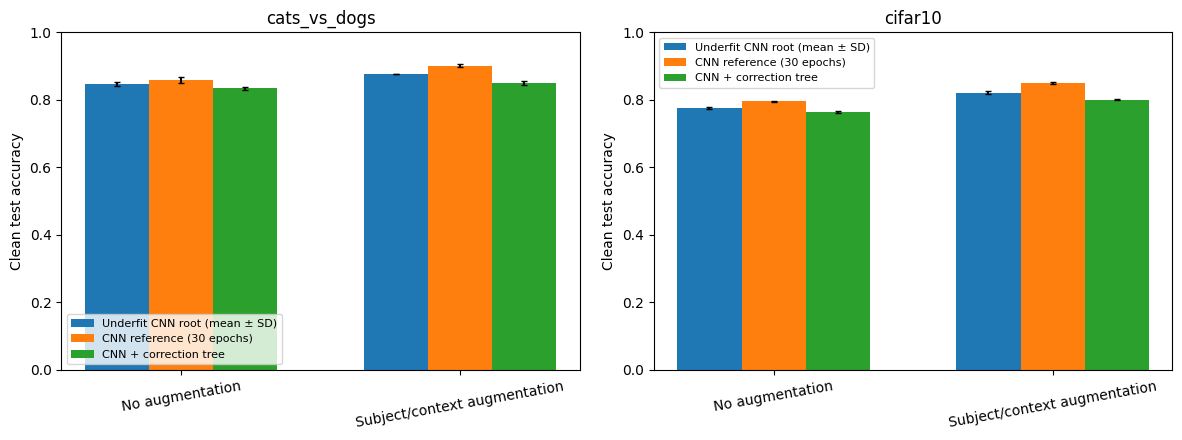

Double-descent cache: 0 complete runs, 0 epoch checkpoints already stored.
DD run: cats_vs_dogs | no_augmentation | width=1 | seed=0 | max_epochs=160
  root noisy-train=0.669, tree noisy-train=0.673, tree val/test=0.581/0.587, nodes=17
DD run: cats_vs_dogs | no_augmentation | width=2 | seed=0 | max_epochs=160
  root noisy-train=0.702, tree noisy-train=0.803, tree val/test=0.595/0.576, nodes=17
DD run: cats_vs_dogs | no_augmentation | width=3 | seed=0 | max_epochs=160
  root noisy-train=0.944, tree noisy-train=0.978, tree val/test=0.582/0.574, nodes=17
DD run: cats_vs_dogs | no_augmentation | width=4 | seed=0 | max_epochs=160
  root noisy-train=0.907, tree noisy-train=1.000, tree val/test=0.601/0.575, nodes=11
DD run: cats_vs_dogs | no_augmentation | width=5 | seed=0 | max_epochs=160
  root noisy-train=1.000, tree noisy-train=1.000, tree val/test=0.622/0.603, nodes=1
DD run: cats_vs_dogs | no_augmentation | width=6 | seed=0 | max_epochs=160
  root noisy-train=1.000, tree noisy-train=1.0

In [ ]:
def _cache_tag(tag):
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", tag)

def fit_complete_tree(model, Xtr, ytr_for_tree, ytr_clean, Xva, yva, Xte, yte, nc, names,
                      seed, strategy="varied", depth=2, width_base=8, target=0.999,
                      max_total=20, max_nodes=TREE_NODE_CAP, epochs=NODE_EP):
    D = make_D(model, (Xtr, Xva, Xte), (ytr_clean, yva, yte), nc, names)
    result, E = run_tree(D, ytr_for_tree, strategy=strategy, depth=depth, base_width=width_base,
                         target=target, max_total=max_total, max_nodes=max_nodes,
                         check_every=2, seed=seed, epochs=epochs)
    return D, E, result

def wilson_interval(correct, n, z=1.959963984540054):
    """Two-sided 95% Wilson interval for one accuracy proportion."""
    if n <= 0: return (float("nan"), float("nan"))
    p = correct / n; den = 1.0 + z*z/n
    center = (p + z*z/(2*n)) / den
    half = z * math.sqrt(p*(1-p)/n + z*z/(4*n*n)) / den
    return max(0.0, center-half), min(1.0, center+half)

def exact_mcnemar(y_true, pred_a, pred_b):
    """Exact two-sided McNemar test using a log-domain binomial tail.

    This avoids both integer-to-float overflow from 2**discordant and loss of
    precision when the discordant count is large. `pred_a` is no augmentation;
    `pred_b` is subject-preserving augmentation.
    """
    y_true = np.asarray(y_true)
    pred_a = np.asarray(pred_a)
    pred_b = np.asarray(pred_b)
    if not (len(y_true) == len(pred_a) == len(pred_b)):
        raise ValueError("y_true and both prediction arrays must have equal lengths")

    a_wrong = pred_a != y_true
    b_wrong = pred_b != y_true
    # a_only: subject-preserving is correct while no-augmentation is wrong.
    a_only = int(np.sum(a_wrong & ~b_wrong))
    # b_only: no-augmentation is correct while subject-preserving is wrong.
    b_only = int(np.sum(~a_wrong & b_wrong))
    discordant = a_only + b_only

    if discordant == 0:
        p_value = 1.0
    else:
        # McNemar's exact two-sided p-value is min(1, 2*P[X <= m]),
        # X~Binomial(discordant, 0.5), m=min(a_only,b_only).
        # Compute P[X=m] in log space, then sum lower-tail terms by recurrence:
        # P[X=j-1] / P[X=j] = j / (n-j+1).
        n = discordant
        m = min(a_only, b_only)
        log_pmf_m = (
            math.lgamma(n + 1)
            - math.lgamma(m + 1)
            - math.lgamma(n - m + 1)
            - n * math.log(2.0)
        )
        scaled_tail = 1.0
        term = 1.0
        for j in range(m, 0, -1):
            term *= j / (n - j + 1)
            scaled_tail += term
        log_p_value = math.log(2.0) + log_pmf_m + math.log(scaled_tail)
        p_value = 1.0 if log_p_value >= 0.0 else math.exp(log_p_value)

    return dict(
        subject_only_correct=a_only,
        no_aug_only_correct=b_only,
        discordant=discordant,
        p_value=float(p_value),
    )

# ---- Validation-only CNN-root recipe selection, inspired by notebook1.ipynb ----
# Choose an intentionally underfit root (90–95% clean train accuracy when attainable),
# then use validation accuracy to select among eligible recipes. The test split is never
# used for selection. One independent selection seed keeps the final three seeds untouched.
ROOT_TUNE_ROWS, ROOT_TUNE_CONFIGS = [], {}
for ds, pack in IM.items():
    for mode, aug in AUGMENTATION_MODES:
        candidates = []
        print(f"\nRoot recipe search: {ds} | {mode}")
        for width, lr, wd in ROOT_TUNE_RECIPES:
            for epochs in ROOT_TUNE_EPOCHS:
                cache_key = _cache_tag(f"root_tune_v5_{PROFILE}_{ds}_{mode}_w{width}_lr{lr}_wd{wd}_ep{epochs}_seed{ROOT_TUNE_SEED}")
                model, _ = train_trunk(pack["Xtr"], pack["ytr"], pack["nc"], width, epochs,
                                       lr=lr, wd=wd, seed=ROOT_TUNE_SEED, aug=aug, opt="sgd", cache_key=cache_key)
                train_logits, _ = extract(model, pack["Xtr"])
                val_logits, _ = extract(model, pack["Xva"])
                train_acc = float((train_logits.argmax(1).numpy() == pack["ytr"]).mean())
                val_acc = float((val_logits.argmax(1).numpy() == pack["yva"]).mean())
                params = sum(p.numel() for p in model.parameters())
                row = dict(dataset=ds, augmentation=mode, width=width, lr=lr, wd=wd, epochs=epochs,
                           root_params=params, train_acc=train_acc, val_acc=val_acc,
                           in_train_band=bool(ROOT_TRAIN_BAND[0] <= train_acc <= ROOT_TRAIN_BAND[1]))
                candidates.append(row); ROOT_TUNE_ROWS.append(row)
                print(f"  w={width:2d} lr={lr:.3g} wd={wd:.1g} ep={epochs:2d}: train={train_acc:.3f} val={val_acc:.3f}")
        grid = pd.DataFrame(candidates)
        eligible = grid[grid.in_train_band]
        if len(eligible):
            chosen = eligible.sort_values(["val_acc", "root_params", "epochs"], ascending=[False, True, True]).iloc[0]
            rule = "best validation accuracy among roots in the 90–95% train band"
        else:
            midpoint = sum(ROOT_TRAIN_BAND) / 2
            grid = grid.assign(distance=(grid.train_acc - midpoint).abs())
            chosen = grid.sort_values(["distance", "val_acc", "root_params", "epochs"], ascending=[True, False, True, True]).iloc[0]
            rule = "no candidate in train band; closest train accuracy to 92.5%, then validation accuracy"
        ROOT_TUNE_CONFIGS[(ds, mode)] = dict(width=int(chosen.width), lr=float(chosen.lr), wd=float(chosen.wd),
                                            epochs=int(chosen.epochs), selection_train_acc=float(chosen.train_acc),
                                            selection_val_acc=float(chosen.val_acc), selection_rule=rule)
        print(f"SELECTED {ds} / {mode}: width={int(chosen.width)}, lr={chosen.lr}, wd={chosen.wd}, epochs={int(chosen.epochs)}; "
              f"train={chosen.train_acc:.3f}, validation={chosen.val_acc:.3f} ({rule})")
ROOT_TUNE_TABLE = pd.DataFrame(ROOT_TUNE_ROWS)
ROOT_TUNE_TABLE.to_csv(OUT / "root_tuning_grid_v5.csv", index=False)
print("Root-tuning grid across conditions:")
display(ROOT_TUNE_TABLE.sort_values(["dataset", "augmentation", "val_acc"], ascending=[True, True, False]).round(4))

# ---- Validation-only correction-tree recipe selection, inspired by notebook1.ipynb ----
# Candidate trees are evaluated on validation data only. To prevent repeated use of the
# actual test split during tuning, the D object uses validation images in both the val and
# placeholder test slots; these placeholder metrics are never used for selection/reporting.
TREE_TUNE_ROWS, TREE_TUNE_CONFIGS = [], {}
for ds, pack in IM.items():
    for mode, aug in AUGMENTATION_MODES:
        root_cfg = ROOT_TUNE_CONFIGS[(ds, mode)]
        root_cache = _cache_tag(f"root_tune_v5_{PROFILE}_{ds}_{mode}_w{root_cfg['width']}_lr{root_cfg['lr']}_wd{root_cfg['wd']}_ep{root_cfg['epochs']}_seed{ROOT_TUNE_SEED}")
        root_model, _ = train_trunk(pack["Xtr"], pack["ytr"], pack["nc"], root_cfg["width"], root_cfg["epochs"],
                                    lr=root_cfg["lr"], wd=root_cfg["wd"], seed=ROOT_TUNE_SEED,
                                    aug=aug, opt="sgd", cache_key=root_cache)
        D_tune = make_D(root_model, (pack["Xtr"], pack["Xva"], pack["Xva"]),
                        (pack["ytr"], pack["yva"], pack["yva"]), pack["nc"], pack["names"])
        candidates = []
        print(f"\nTree recipe search: {ds} | {mode}")
        for gi, (strategy, depth, base_width) in enumerate(TREE_TUNING_GRID):
            result, E_tune = run_tree(D_tune, pack["ytr"], strategy=strategy, depth=depth,
                                      base_width=base_width, target=INTERPOLATION_THRESHOLD,
                                      max_total=CLEAN_TREE_BUDGET[ds], max_nodes=TREE_NODE_CAPS[ds],
                                      check_every=2, seed=7000 + gi, epochs=NODE_EP)
            row = dict(dataset=ds, augmentation=mode, strategy=strategy, depth=depth, base_width=base_width,
                       train_acc=result["train_acc"], val_acc=result["val_acc"], nodes=result["nodes"],
                       total_params=result["total_params"], reached_target=bool(result["reached"]), reason=result["reason"])
            candidates.append(row); TREE_TUNE_ROWS.append(row)
            print(f"  {strategy:6s} depth={depth} node_width={base_width:2d}: train={result['train_acc']:.4f} "
                  f"val={result['val_acc']:.3f} nodes={result['nodes']} params={result['total_params']} "
                  f"reached={result['reached']} ({result['reason']})")
            del E_tune
        grid = pd.DataFrame(candidates)
        eligible = grid[grid.reached_target]
        if len(eligible):
            pool = eligible
            rule_prefix = "target-reaching candidates"
        else:
            pool = grid
            rule_prefix = "no tree reached 99.9%; all candidates"
        best_val = float(pool.val_acc.max())
        se = math.sqrt(max(1e-12, best_val * (1 - best_val) / len(pack["yva"])))
        within_one_se = pool[pool.val_acc >= best_val - se]
        chosen = within_one_se.sort_values(["total_params", "val_acc"], ascending=[True, False]).iloc[0]
        rule = f"{rule_prefix}; smallest model within one validation standard error of best val accuracy"
        TREE_TUNE_CONFIGS[(ds, mode)] = dict(strategy=str(chosen.strategy), depth=int(chosen.depth),
                                             base_width=int(chosen.base_width), selection_val_acc=float(chosen.val_acc),
                                             selection_train_acc=float(chosen.train_acc), selection_reached=bool(chosen.reached_target),
                                             selection_nodes=int(chosen.nodes), selection_params=int(chosen.total_params),
                                             selection_rule=rule)
        print(f"SELECTED TREE {ds}/{mode}: {TREE_TUNE_CONFIGS[(ds, mode)]}")
        del root_model, D_tune
        if DEVICE == "cuda": torch.cuda.empty_cache()
TREE_TUNE_TABLE = pd.DataFrame(TREE_TUNE_ROWS)
TREE_TUNE_TABLE.to_csv(OUT / "tree_tuning_grid_v5.csv", index=False)
print("Correction-tree tuning grid (validation based):")
display(TREE_TUNE_TABLE.sort_values(["dataset", "augmentation", "val_acc"], ascending=[True, True, False]).round(4))

# ---- Clean-label matched augmentation experiment ----
CLEAN_ROWS, CLEAN_ARTIFACTS, CLEAN_TEST_PREDS = [], {}, {}
for ds, pack in IM.items():
    CLEAN_ARTIFACTS[ds] = {}; CLEAN_TEST_PREDS[ds] = {}
    for mode, aug in AUGMENTATION_MODES:
        CLEAN_TEST_PREDS[ds][mode] = {}
    for seed in CLEAN_SEEDS:
        for mode, aug in AUGMENTATION_MODES:
            print(f"\nClean-label experiment: {ds} | {mode} | seed={seed} | selected root={ROOT_TUNE_CONFIGS[(ds, mode)]}")
            cfg = ROOT_TUNE_CONFIGS[(ds, mode)]
            cache_key = _cache_tag(f"clean_v5_{PROFILE}_{ds}_{mode}_n{len(pack['ytr'])}_r{pack['Xtr'].shape[-1]}_w{cfg['width']}_ep{cfg['epochs']}_lr{cfg['lr']}_wd{cfg['wd']}_seed{seed}")
            model, _ = train_trunk(pack["Xtr"], pack["ytr"], pack["nc"], cfg["width"], cfg["epochs"],
                                   lr=cfg["lr"], wd=cfg["wd"], seed=seed, aug=aug, opt="sgd", cache_key=cache_key)
            tree_cfg = TREE_TUNE_CONFIGS[(ds, mode)]
            D, E, result = fit_complete_tree(model, pack["Xtr"], pack["ytr"], pack["ytr"],
                                             pack["Xva"], pack["yva"], pack["Xte"], pack["yte"],
                                             pack["nc"], pack["names"], seed=1000+seed,
                                             strategy=tree_cfg["strategy"], depth=tree_cfg["depth"], width_base=tree_cfg["base_width"],
                                             target=INTERPOLATION_THRESHOLD, max_total=CLEAN_TREE_BUDGET[ds],
                                             max_nodes=TREE_NODE_CAPS[ds], epochs=NODE_EP)
            root_metrics, full_metrics = cnn_acc(D), E.acc()

            # Reference: the selected CNN recipe trained longer, without a tree, to
            # distinguish the tree's memorization gain from ordinary CNN convergence.
            ref_cache = _cache_tag(f"reference_v5_{PROFILE}_{ds}_{mode}_n{len(pack['ytr'])}_r{pack['Xtr'].shape[-1]}_w{cfg['width']}_ep{REF_EPOCHS}_lr{cfg['lr']}_wd{cfg['wd']}_seed{seed}")
            ref_model, _ = train_trunk(pack["Xtr"], pack["ytr"], pack["nc"], cfg["width"], REF_EPOCHS,
                                       lr=cfg["lr"], wd=cfg["wd"], seed=seed, aug=aug, opt="sgd", cache_key=ref_cache)
            ref_tr_logits, _ = extract(ref_model, pack["Xtr"])
            ref_va_logits, _ = extract(ref_model, pack["Xva"])
            ref_te_logits, _ = extract(ref_model, pack["Xte"])
            reference_metrics = dict(
                tr=float((ref_tr_logits.argmax(1).numpy() == pack["ytr"]).mean()),
                va=float((ref_va_logits.argmax(1).numpy() == pack["yva"]).mean()),
                te=float((ref_te_logits.argmax(1).numpy() == pack["yte"]).mean()))
            del ref_model, ref_tr_logits, ref_va_logits, ref_te_logits
            if DEVICE == "cuda": torch.cuda.empty_cache()
            off = D["ntr"] + D["nva"]
            root_test_pred = D["logits"][off:].argmax(1).numpy()
            tree_test_pred = E.pred(E.Z())[off:]
            root_lo, root_hi = wilson_interval(int(np.sum(root_test_pred == pack["yte"])), len(pack["yte"]))
            tree_lo, tree_hi = wilson_interval(int(np.sum(tree_test_pred == pack["yte"])), len(pack["yte"]))
            CLEAN_ROWS.append(dict(dataset=ds, augmentation=mode, seed=seed,
                                   root_train_acc=root_metrics["tr"], root_val_acc=root_metrics["va"], root_test_acc=root_metrics["te"],
                                   root_test_ci_low=root_lo, root_test_ci_high=root_hi,
                                   reference_root_train_acc=reference_metrics["tr"],
                                   reference_root_val_acc=reference_metrics["va"],
                                   reference_root_test_acc=reference_metrics["te"],
                                   tree_train_acc=full_metrics["tr"], tree_val_acc=full_metrics["va"], tree_test_acc=full_metrics["te"],
                                   tree_test_ci_low=tree_lo, tree_test_ci_high=tree_hi,
                                   tree_strategy=tree_cfg["strategy"], tree_depth=tree_cfg["depth"],
                                   tree_base_width=tree_cfg["base_width"],
                                   tree_nodes=result["nodes"], total_params=result["total_params"],
                                   reached_target=bool(result["reached"]), tree_reason=result["reason"]))
            CLEAN_TEST_PREDS[ds][mode][seed] = tree_test_pred
            # Retain the first augmented artifact for the local loss-landscape plot.
            CLEAN_ARTIFACTS[ds].setdefault(mode, (model, D, E))
            print(f"  underfit CNN train/test={root_metrics['tr']:.3f}/{root_metrics['te']:.3f}; "
                  f"long-trained CNN reference train/test={reference_metrics['tr']:.3f}/{reference_metrics['te']:.3f}; "
                  f"CNN+tree train/val/test={full_metrics['tr']:.4f}/{full_metrics['va']:.3f}/{full_metrics['te']:.3f}; "
                  f"tree={tree_cfg['strategy']}/L{tree_cfg['depth']}/w{tree_cfg['base_width']}, "
                  f"nodes={result['nodes']} ({result['reason']})")

CLEAN_TABLE = pd.DataFrame(CLEAN_ROWS)
CLEAN_TABLE.to_csv(OUT / "clean_augmentation_comparison_v5.csv", index=False)
CLEAN_SUMMARY = (CLEAN_TABLE.groupby(["dataset", "augmentation"], as_index=False)
                 .agg(n_seeds=("seed", "nunique"),
                      root_train_acc=("root_train_acc", "mean"), root_val_acc=("root_val_acc", "mean"),
                      root_test_acc=("root_test_acc", "mean"), root_test_sd=("root_test_acc", "std"),
                      reference_root_train_acc=("reference_root_train_acc", "mean"),
                      reference_root_val_acc=("reference_root_val_acc", "mean"),
                      reference_root_test_acc=("reference_root_test_acc", "mean"),
                      reference_root_test_sd=("reference_root_test_acc", "std"),
                      tree_train_acc=("tree_train_acc", "mean"), tree_val_acc=("tree_val_acc", "mean"),
                      tree_test_acc=("tree_test_acc", "mean"), tree_test_sd=("tree_test_acc", "std"),
                      tree_nodes=("tree_nodes", "mean"), reached_rate=("reached_target", "mean")))
CLEAN_SUMMARY.to_csv(OUT / "clean_augmentation_summary_v5.csv", index=False)
CLEAN_PAIRED_ROWS = []
for ds, pack in IM.items():
    for seed in CLEAN_SEEDS:
        paired = exact_mcnemar(pack["yte"], CLEAN_TEST_PREDS[ds]["no_augmentation"][seed], CLEAN_TEST_PREDS[ds]["subject_preserving"][seed])
        CLEAN_PAIRED_ROWS.append(dict(dataset=ds, seed=seed, n_test=len(pack["yte"]), **paired))
CLEAN_PAIRED_TABLE = pd.DataFrame(CLEAN_PAIRED_ROWS)
CLEAN_PAIRED_TABLE.to_csv(OUT / "clean_augmentation_paired_test_v5.csv", index=False)
print("Per-seed clean-label results:"); display(CLEAN_TABLE.round(4))
print("Mean comparison (SD across training seeds, not a test-set CI):"); display(CLEAN_SUMMARY.round(4))
print("Per-seed paired McNemar results (same held-out examples):"); display(CLEAN_PAIRED_TABLE.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, ds in zip(axes, IM.keys()):
    g = CLEAN_SUMMARY[CLEAN_SUMMARY.dataset == ds].set_index("augmentation")
    labels = ["No augmentation", "Subject/context augmentation"]
    x = np.arange(2); width = 0.34
    root_vals = [g.loc["no_augmentation", "root_test_acc"], g.loc["subject_preserving", "root_test_acc"]]
    ref_vals = [g.loc["no_augmentation", "reference_root_test_acc"], g.loc["subject_preserving", "reference_root_test_acc"]]
    tree_vals = [g.loc["no_augmentation", "tree_test_acc"], g.loc["subject_preserving", "tree_test_acc"]]
    root_sd = [0 if pd.isna(v) else v for v in [g.loc["no_augmentation", "root_test_sd"], g.loc["subject_preserving", "root_test_sd"]]]
    ref_sd = [0 if pd.isna(v) else v for v in [g.loc["no_augmentation", "reference_root_test_sd"], g.loc["subject_preserving", "reference_root_test_sd"]]]
    tree_sd = [0 if pd.isna(v) else v for v in [g.loc["no_augmentation", "tree_test_sd"], g.loc["subject_preserving", "tree_test_sd"]]]
    bar_w = 0.23
    ax.bar(x-bar_w, root_vals, bar_w, yerr=root_sd, capsize=2, label="Underfit CNN root (mean ± SD)")
    ax.bar(x, ref_vals, bar_w, yerr=ref_sd, capsize=2, label=f"CNN reference ({REF_EPOCHS} epochs)")
    ax.bar(x+bar_w, tree_vals, bar_w, yerr=tree_sd, capsize=2, label="CNN + correction tree")
    ax.set_xticks(x, labels, rotation=10); ax.set_ylim(0, 1); ax.set_ylabel("Clean test accuracy"); ax.set_title(ds); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "clean_augmentation_comparison_v5.png", dpi=150); plt.show()

# ---- Double descent: noisy labels, dense capacity grid, multiple seeds, long epoch schedules ----
# Each width/seed/augmentation run trains through its configured maximum epochs and saves
# checkpoint metrics. This avoids early stopping hiding the overfitting time course.
DD_RAW_PATH = OUT / "double_descent_raw_v5.csv"
DD_EPOCH_PATH = OUT / "double_descent_epoch_raw_v5.csv"

def _load_versioned_csv(path, required=()):
    if not path.exists(): return []
    try:
        df = pd.read_csv(path)
        if "experiment_version" not in df.columns or not (df["experiment_version"] == DD_CACHE_VERSION).all(): return []
        if any(c not in df.columns for c in required): return []
        return df.to_dict("records")
    except Exception:
        return []

DD_ROWS = _load_versioned_csv(DD_RAW_PATH, required=("dataset", "augmentation", "width", "seed", "tree_val_error"))
DD_EPOCH_ROWS = _load_versioned_csv(DD_EPOCH_PATH, required=("dataset", "augmentation", "width", "seed", "epoch", "root_val_error"))
def _dd_key(row):
    return (str(row["dataset"]), str(row["augmentation"]), int(row["width"]), int(row["seed"]))
_raw_keys = {_dd_key(r) for r in DD_ROWS}
_epoch_map = {}
for row in DD_EPOCH_ROWS:
    _epoch_map.setdefault(_dd_key(row), set()).add(int(row["epoch"]))
_incomplete = set()
for key in _raw_keys:
    dataset = key[0]
    expected = set(map(int, DD_EPOCH_CHECKPOINTS[dataset]))
    if not expected.issubset(_epoch_map.get(key, set())):
        _incomplete.add(key)
if _incomplete:
    print(f"Removing {len(_incomplete)} cached rows with incomplete epoch checkpoints; those runs will be retrained.")
    DD_ROWS = [r for r in DD_ROWS if _dd_key(r) not in _incomplete]
    DD_EPOCH_ROWS = [r for r in DD_EPOCH_ROWS if _dd_key(r) not in _incomplete]
    pd.DataFrame(DD_ROWS).to_csv(DD_RAW_PATH, index=False)
    pd.DataFrame(DD_EPOCH_ROWS).to_csv(DD_EPOCH_PATH, index=False)
completed = {_dd_key(r) for r in DD_ROWS}
print(f"Double-descent cache: {len(completed)} complete runs, {len(DD_EPOCH_ROWS)} epoch checkpoints already stored.")

for ds, pack in IM.items():
    n = min(DD_N[ds], len(pack["ytr"]))
    nva = min(DD_VAL_N[ds], len(pack["yva"]))
    nte = min(DD_TEST_N[ds], len(pack["yte"]))
    Xdd, yclean = pack["Xtr"][:n], pack["ytr"][:n]
    Xva, yva = pack["Xva"][:nva], pack["yva"][:nva]
    Xte, yte = pack["Xte"][:nte], pack["yte"][:nte]
    for seed in DD_SEEDS:
        ynoisy = add_noise(yclean, pack["nc"], NOISE_RATE, np.random.RandomState(5000 + seed))
        for mode, aug in AUGMENTATION_MODES:
            for width in DD_WIDTHS:
                run_key = (ds, mode, int(width), int(seed))
                if run_key in completed:
                    continue
                print(f"DD run: {ds} | {mode} | width={width} | seed={seed} | max_epochs={DD_EPOCHS[ds]}")
                model, snapshots = train_trunk(Xdd, ynoisy, pack["nc"], width, DD_EPOCHS[ds],
                                               lr=1.5e-3, wd=0.0, seed=seed, aug=aug, opt="adam",
                                               checkpoints=DD_EPOCH_CHECKPOINTS[ds], stop_train_acc=None)
                # Keep the epoch axis explicit: log root train fit and clean validation error at checkpoints.
                for epoch in DD_EPOCH_CHECKPOINTS[ds]:
                    if epoch not in snapshots: continue
                    model.load_state_dict(snapshots[epoch]); model.eval()
                    train_logits, _ = extract(model, Xdd)
                    val_logits, _ = extract(model, Xva)
                    root_tr_acc = float((train_logits.argmax(1).numpy() == ynoisy).mean())
                    root_va_acc = float((val_logits.argmax(1).numpy() == yva).mean())
                    DD_EPOCH_ROWS.append(dict(experiment_version=DD_CACHE_VERSION, dataset=ds, augmentation=mode,
                                              width=width, seed=seed, epoch=epoch, root_train_noisy_acc=root_tr_acc,
                                              root_val_acc=root_va_acc, root_val_error=1-root_va_acc))
                # Ensure the tree is fitted on the final saved epoch even if the schedule changes later.
                model.load_state_dict(snapshots[max(snapshots)])
                D = make_D(model, (Xdd, Xva, Xte), (yclean, yva, yte), pack["nc"], pack["names"])
                root_metrics = cnn_acc(D, ynoisy)
                E = TreeEnsemble(D, ynoisy, get_layer_widths(2, max(2, width)), make_strategy("varied"),
                                 seed=seed*1000 + width, max_nodes=DD_NODE_BUDGET[ds]+1,
                                 max_depth=MAX_DEPTH, max_ep=min(40, NODE_EP), lr=NODE_LR, bs=NODE_BS)
                tree_result = E.fit(target=None, max_total=DD_NODE_BUDGET[ds], check_every=DD_CHECK_EVERY[ds])
                full = E.acc()
                row = dict(experiment_version=DD_CACHE_VERSION, dataset=ds, augmentation=mode, width=width, seed=seed,
                           root_params=D["tparams"], total_params=tree_result["total_params"],
                           root_train_noisy_acc=root_metrics["tr"], root_val_acc=root_metrics["va"], root_val_error=1-root_metrics["va"],
                           root_test_acc=root_metrics["te"], tree_train_noisy_acc=full["tr"], tree_train_clean_acc=full["clean"],
                           tree_val_acc=full["va"], tree_val_error=1-full["va"], tree_test_acc=full["te"], tree_error=1-full["te"],
                           tree_nodes=tree_result["nodes"], reached_interpolation=bool(full["tr"] >= INTERPOLATION_THRESHOLD),
                           max_epochs=DD_EPOCHS[ds], stop_reason=tree_result["reason"])
                DD_ROWS.append(row); completed.add(run_key)
                # Write after each completed model; the sweep can be resumed safely after interruption.
                pd.DataFrame(DD_ROWS).to_csv(DD_RAW_PATH, index=False)
                pd.DataFrame(DD_EPOCH_ROWS).to_csv(DD_EPOCH_PATH, index=False)
                print(f"  root noisy-train={root_metrics['tr']:.3f}, tree noisy-train={full['tr']:.3f}, "
                      f"tree val/test={full['va']:.3f}/{full['te']:.3f}, nodes={tree_result['nodes']}")

DD_RAW = pd.DataFrame(DD_ROWS)
DD_EPOCH_RAW = pd.DataFrame(DD_EPOCH_ROWS)
DD_RAW.to_csv(DD_RAW_PATH, index=False); DD_EPOCH_RAW.to_csv(DD_EPOCH_PATH, index=False)
if DD_RAW.empty:
    raise RuntimeError("No double-descent runs are available. Check the run configuration or resume cache.")
DD_GROUPED = (DD_RAW.groupby(["dataset", "augmentation", "width"], as_index=False)
              .agg(root_params=("root_params", "mean"), total_params=("total_params", "mean"),
                   root_train_acc=("root_train_noisy_acc", "mean"), root_train_sd=("root_train_noisy_acc", "std"),
                   root_val_acc=("root_val_acc", "mean"), root_val_error=("root_val_error", "mean"), root_val_error_sd=("root_val_error", "std"),
                   root_test_acc=("root_test_acc", "mean"), root_test_sd=("root_test_acc", "std"),
                   tree_train_acc=("tree_train_noisy_acc", "mean"), tree_train_sd=("tree_train_noisy_acc", "std"),
                   tree_val_acc=("tree_val_acc", "mean"), tree_val_error=("tree_val_error", "mean"), tree_val_error_sd=("tree_val_error", "std"),
                   tree_test_acc=("tree_test_acc", "mean"), tree_test_sd=("tree_test_acc", "std"), n_seeds=("seed", "nunique")))
DD_GROUPED.to_csv(OUT / "double_descent_summary_v5.csv", index=False)
DD_EPOCH_SUMMARY = (DD_EPOCH_RAW.groupby(["dataset", "augmentation", "width", "epoch"], as_index=False)
                    .agg(root_train_acc=("root_train_noisy_acc", "mean"), root_val_acc=("root_val_acc", "mean"),
                         root_val_error=("root_val_error", "mean"), root_val_error_sd=("root_val_error", "std"), n_seeds=("seed", "nunique")))
DD_EPOCH_SUMMARY.to_csv(OUT / "double_descent_epoch_summary_v5.csv", index=False)

# Validation-based heuristic: every seed must interpolate, then a consistent error rise
# and later fall must occur across the dense width grid. Test metrics never enter this verdict.
def double_descent_verdict(raw, grouped, dataset, augmentation, model_kind):
    g = grouped[(grouped.dataset == dataset) & (grouped.augmentation == augmentation)].sort_values("width").reset_index(drop=True)
    r = raw[(raw.dataset == dataset) & (raw.augmentation == augmentation)].copy()
    n_seeds = int(r.seed.nunique()) if not r.empty else 0
    if g.empty or r.empty:
        return dict(status="inconclusive", reason="no measured curve", peak_width=None, rise=np.nan, drop=np.nan,
                    seed_support=0, n_seeds=n_seeds, peak_index=None, params=None)
    if model_kind == "root":
        train_col, err_col, params_col = "root_train_noisy_acc", "root_val_error", "root_params"
        gtrain, gerr = "root_train_acc", "root_val_error"
    else:
        train_col, err_col, params_col = "tree_train_noisy_acc", "tree_val_error", "total_params"
        gtrain, gerr = "tree_train_acc", "tree_val_error"
    widths = g.width.astype(int).to_numpy()
    all_seed_interp = []
    for w in widths:
        rw = r[r.width.astype(int) == int(w)]
        all_seed_interp.append(len(rw) == n_seeds and bool((rw[train_col] >= INTERPOLATION_THRESHOLD).all()))
    ip = np.where(np.asarray(all_seed_interp, dtype=bool))[0]
    if len(ip) == 0:
        max_acc = float(r[train_col].max())
        return dict(status="inconclusive", reason=f"not every seed reached {INTERPOLATION_THRESHOLD:.1%} noisy-label train accuracy (best run={max_acc:.3f})", peak_width=None, rise=np.nan, drop=np.nan, seed_support=0, n_seeds=n_seeds, peak_index=None, params=None)
    start = max(0, int(ip[0])-1)
    err = g[gerr].to_numpy()
    if len(err)-start < 3:
        return dict(status="inconclusive", reason="fewer than three widths remain after interpolation", peak_width=None, rise=np.nan, drop=np.nan, seed_support=0, n_seeds=n_seeds, peak_index=None, params=None)
    peak = start + int(np.argmax(err[start:]))
    if peak <= 0 or peak >= len(err)-1:
        return dict(status="inconclusive", reason="validation-error peak is at a sweep boundary", peak_width=int(widths[peak]), rise=np.nan, drop=np.nan, seed_support=0, n_seeds=n_seeds, peak_index=peak, params=float(g.loc[peak, params_col]))
    rise = float(err[peak] - np.min(err[:peak]))
    drop = float(err[peak] - np.min(err[peak+1:]))
    peak_width = int(widths[peak]); seed_support = 0
    for seed in sorted(r.seed.unique()):
        one = r[r.seed == seed].sort_values("width")
        one_widths = one.width.astype(int).tolist()
        if peak_width not in one_widths: continue
        e = one[err_col].to_numpy(); p = one_widths.index(peak_width)
        if p > 0 and p < len(e)-1:
            if (e[p] - np.min(e[:p]) >= 0.01) and (e[p] - np.min(e[p+1:]) >= 0.01):
                seed_support += 1
    # For four seeds, require at least three to show the same rise-and-fall; all seeds must interpolate.
    tol = 0.01
    if rise >= tol and drop >= tol and n_seeds >= 3 and seed_support >= math.ceil(0.75*n_seeds):
        status = "supported by this sweep (exploratory)"
    elif rise >= tol and drop >= tol and seed_support > 0:
        status = "suggestive, not robustly established"
    else:
        status = "no convincing double descent in this sweep"
    reason = (f"validation-error peak width={peak_width}; rise={rise:.3f}, later drop={drop:.3f}; "
              f"matching seeds={seed_support}/{n_seeds}; all seeds interpolate; heuristic threshold={tol:.3f}")
    return dict(status=status, reason=reason, peak_width=peak_width, rise=rise, drop=drop,
                seed_support=seed_support, n_seeds=n_seeds, peak_index=peak, params=float(g.loc[peak, params_col]))

DD_VERDICTS = {}
for ds in IM:
    for mode, _ in AUGMENTATION_MODES:
        for kind in ("root", "tree"):
            DD_VERDICTS[(ds, mode, kind)] = double_descent_verdict(DD_RAW, DD_GROUPED, ds, mode, kind)
            v = DD_VERDICTS[(ds, mode, kind)]
            print(f"Double-descent verdict | {ds} | {mode} | {kind}: {v['status']} — {v['reason']}")

# Evaluate root-only double-descent shape at every saved epoch checkpoint as well.
# This is separate from the final-epoch root+tree capacity sweep; only validation error
# is used in these verdicts and test labels are excluded.
DD_EPOCH_VERDICT_ROWS = []
param_cols = DD_RAW[["dataset", "augmentation", "width", "seed", "root_params"]].drop_duplicates()
for ds in IM:
    for mode, _ in AUGMENTATION_MODES:
        epochs_here = sorted(DD_EPOCH_RAW[(DD_EPOCH_RAW.dataset == ds) & (DD_EPOCH_RAW.augmentation == mode)].epoch.unique())
        for epoch in epochs_here:
            raw_ep = DD_EPOCH_RAW[(DD_EPOCH_RAW.dataset == ds) & (DD_EPOCH_RAW.augmentation == mode) & (DD_EPOCH_RAW.epoch == epoch)].merge(
                param_cols, on=["dataset", "augmentation", "width", "seed"], how="left")
            grouped_ep = (raw_ep.groupby("width", as_index=False)
                          .agg(root_params=("root_params", "mean"), root_train_acc=("root_train_noisy_acc", "mean"),
                               root_val_error=("root_val_error", "mean")))
            if raw_ep.empty:
                continue
            verdict = double_descent_verdict(raw_ep, grouped_ep, ds, mode, "root")
            DD_EPOCH_VERDICT_ROWS.append(dict(dataset=ds, augmentation=mode, epoch=int(epoch), **verdict))
DD_EPOCH_VERDICTS = pd.DataFrame(DD_EPOCH_VERDICT_ROWS)
DD_EPOCH_VERDICTS.to_csv(OUT / "double_descent_epoch_verdicts_v5.csv", index=False)
print("Root-only epoch-wise double-descent checks (validation based):")
if len(DD_EPOCH_VERDICTS):
    display(DD_EPOCH_VERDICTS[["dataset", "augmentation", "epoch", "status", "peak_width", "rise", "drop", "seed_support", "n_seeds"]].round(4))
else:
    print("No complete epoch checkpoint curves are available; rerun the double-descent cell after checking its saved run log.")

# Capacity curves: top = noisy-label train accuracy; bottom = clean validation error.
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for col, ds in enumerate(IM.keys()):
    for mode, _ in AUGMENTATION_MODES:
        g = DD_GROUPED[(DD_GROUPED.dataset == ds) & (DD_GROUPED.augmentation == mode)].sort_values("width")
        mode_label = "no aug" if mode == "no_augmentation" else "subject aug"
        axes[0, col].plot(g.root_params, g.root_train_acc, "o-", label=f"root / {mode_label}")
        axes[0, col].plot(g.total_params, g.tree_train_acc, "s--", label=f"root + tree / {mode_label}")
        axes[1, col].plot(g.root_params, g.root_val_error, "o-", label=f"root / {mode_label}")
        axes[1, col].plot(g.total_params, g.tree_val_error, "s--", label=f"root + tree / {mode_label}")
    axes[0, col].axhline(INTERPOLATION_THRESHOLD, ls=":", color="gray", label="interpolation target")
    axes[0, col].set_xscale("log"); axes[0, col].set_ylim(0, 1.02); axes[0, col].set_ylabel("Noisy-label training accuracy")
    axes[1, col].set_xscale("log"); axes[1, col].set_ylabel("Clean validation error")
    axes[0, col].set_title(f"{ds}: capacity sweep"); axes[1, col].set_title(f"{ds}: validation error (verdict metric)")
    for ax in (axes[0, col], axes[1, col]): ax.set_xlabel("Trainable parameters (log scale)"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT / "double_descent_capacity_sweep_v5.png", dpi=150); plt.show()

# Epoch curves for several widths show the time course of memorizing noisy labels.
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for col, ds in enumerate(IM.keys()):
    widths_available = sorted(DD_EPOCH_SUMMARY[DD_EPOCH_SUMMARY.dataset == ds].width.unique())
    desired = [4, 8, 16, 32, max(widths_available)]
    selected_widths = [w for w in sorted(set(desired)) if w in widths_available]
    for mode, _ in AUGMENTATION_MODES:
        mode_label = "no aug" if mode == "no_augmentation" else "subject aug"
        for width in selected_widths:
            g = DD_EPOCH_SUMMARY[(DD_EPOCH_SUMMARY.dataset == ds) & (DD_EPOCH_SUMMARY.augmentation == mode) & (DD_EPOCH_SUMMARY.width == width)].sort_values("epoch")
            if g.empty: continue
            axes[0, col].plot(g.epoch, g.root_train_acc, marker="o", ms=3, label=f"w={width} {mode_label}")
            axes[1, col].plot(g.epoch, g.root_val_error, marker="o", ms=3, label=f"w={width} {mode_label}")
    axes[0, col].set_title(f"{ds}: noisy-label train fit vs epochs"); axes[0, col].set_ylabel("Training accuracy")
    axes[1, col].set_title(f"{ds}: clean validation error vs epochs"); axes[1, col].set_ylabel("Validation error")
    axes[0, col].set_xlabel("Epoch checkpoint"); axes[1, col].set_xlabel("Epoch checkpoint")
    axes[0, col].legend(fontsize=6, ncol=2); axes[1, col].legend(fontsize=6, ncol=2)
plt.tight_layout(); plt.savefig(OUT / "double_descent_epoch_sweeps_v5.png", dpi=150); plt.show()

display(DD_GROUPED.round(4))
print(f"Double-descent raw runs saved to {DD_RAW_PATH}; epoch-wise metrics saved to {DD_EPOCH_PATH}.")


## 5. Requirement 2 — multiple tree-type models with majority voting

Each member is an independent CNN-root + correction-tree model trained from a bootstrapped sample. The predictions are combined using class-wise majority voting. Member and vote test accuracies are reported; the ensemble only earns a claimed improvement if its measured vote accuracy exceeds the member baseline.


In [ ]:
ENSEMBLE_ROWS, ENSEMBLE_ARTIFACTS = [], {}
for ds, pack in IM.items():
    member_preds, member_accs, artifacts = [], [], []
    Xtr, ytr = pack["Xtr"], pack["ytr"]
    test_offset = None
    for member in range(ENSEMBLE_MEMBERS):
        rng = np.random.RandomState(9000 + member)
        boot = rng.randint(0, len(ytr), size=len(ytr))
        Xb, yb = Xtr[boot], ytr[boot]
        print(f"\nEnsemble member {member+1}/{ENSEMBLE_MEMBERS}: {ds}")
        root_cfg = ROOT_TUNE_CONFIGS[(ds, "subject_preserving")]
        model, _ = train_trunk(Xb, yb, pack["nc"], root_cfg["width"], root_cfg["epochs"],
                            lr=root_cfg["lr"], wd=root_cfg["wd"], seed=300 + member, aug="subject", opt="sgd",
                            cache_key=_cache_tag(f"ensemble_v5_{PROFILE}_{ds}_n{len(yb)}_r{Xb.shape[-1]}_m{member}_w{root_cfg['width']}_ep{root_cfg['epochs']}_lr{root_cfg['lr']}_wd{root_cfg['wd']}"))
        tree_cfg = TREE_TUNE_CONFIGS[(ds, "subject_preserving")]
        D, E, result = fit_complete_tree(model, Xb, yb, yb, pack["Xva"], pack["yva"], pack["Xte"], pack["yte"],
                                         pack["nc"], pack["names"], seed=400 + member,
                                         strategy=tree_cfg["strategy"], depth=tree_cfg["depth"], width_base=tree_cfg["base_width"],
                                         target=INTERPOLATION_THRESHOLD, max_total=ENSEMBLE_TREE_BUDGET[ds],
                                         max_nodes=TREE_NODE_CAPS[ds], epochs=NODE_EP)
        Z = E.Z(); pred = E.pred(Z); off = D["ntr"] + D["nva"]
        test_pred = pred[off:]; acc = float((test_pred == pack["yte"]).mean())
        member_preds.append(test_pred); member_accs.append(acc); artifacts.append((model, D, E))
        ENSEMBLE_ROWS.append(dict(dataset=ds, member=member+1, test_accuracy=acc,
                                  train_accuracy=result["train_acc"], val_accuracy=result["val_acc"],
                                  tree_nodes=result["nodes"], total_params=result["total_params"]))
        print(f"  member test accuracy={acc:.3f}; tree nodes={result['nodes']}; stop={result['reason']}")
    votes = np.stack(member_preds, axis=0)
    majority_pred = np.asarray([np.bincount(votes[:, i], minlength=pack["nc"]).argmax() for i in range(votes.shape[1])])
    vote_acc = float((majority_pred == pack["yte"]).mean())
    ENSEMBLE_ARTIFACTS[ds] = dict(members=artifacts, member_preds=member_preds, majority_pred=majority_pred, member_accs=member_accs, vote_acc=vote_acc)
    ENSEMBLE_ROWS.append(dict(dataset=ds, member="majority_vote", test_accuracy=vote_acc,
                              train_accuracy=np.nan, val_accuracy=np.nan, tree_nodes=np.nan, total_params=np.nan))
    print(f"{ds}: mean member accuracy={np.mean(member_accs):.3f}; majority-vote accuracy={vote_acc:.3f}")

ENSEMBLE_TABLE = pd.DataFrame(ENSEMBLE_ROWS)
ENSEMBLE_TABLE.to_csv(OUT / "majority_vote_ensemble.csv", index=False)
display(ENSEMBLE_TABLE.round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, ds in zip(axes, IM.keys()):
    g = ENSEMBLE_TABLE[ENSEMBLE_TABLE.dataset == ds]
    labels = [f"Tree {i}" for i in range(1, ENSEMBLE_MEMBERS+1)] + ["Majority vote"]
    vals = list(g[g.member != "majority_vote"].test_accuracy) + [float(g[g.member == "majority_vote"].test_accuracy.iloc[0])]
    ax.bar(labels, vals); ax.set_ylim(0, 1); ax.set_ylabel("Clean test accuracy"); ax.set_title(ds); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(OUT / "majority_vote_ensemble.png", dpi=150); plt.show()

## 6. Requirement 3 — bias² and variance versus sample count and epochs

For each dataset, models are trained at three sample counts and evaluated at multiple epoch checkpoints over three seeds. Probability-space bias² and variance are computed on held-out examples for the complete CNN-root + correction-tree predictor. This is an empirical classification diagnostic rather than the exact classical regression decomposition; the small-checkpoint tree budget keeps the diagnostic tractable.


In [ ]:
def tree_probabilities(Z, nc):
    Z = np.asarray(Z, dtype=np.float64)
    if nc == 2:
        p1 = 1.0 / (1.0 + np.exp(-np.clip(Z[:, 0], -35, 35)))
        return np.stack([1-p1, p1], axis=1)
    shifted = Z - Z.max(axis=1, keepdims=True)
    ex = np.exp(shifted)
    return ex / ex.sum(axis=1, keepdims=True)

BV_PREDICTIONS = {}
BV_ROWS = []
for ds, pack in IM.items():
    Xtest_bv, ytest_bv = pack["Xte"][:BIAS_TEST_N], pack["yte"][:BIAS_TEST_N]
    sizes = sorted(set(min(n, len(pack["ytr"])) for n in BIAS_SIZES))
    for n in sizes:
        for seed in BIAS_SEEDS:
            Xsub, ysub = pack["Xtr"][:n], pack["ytr"][:n]
            print(f"Bias/variance root fit: {ds} | n={n} | seed={seed}")
            model, snapshots = train_trunk(Xsub, ysub, pack["nc"], w=8, ep=max(BIAS_EPOCHS),
                                           lr=0.04, wd=5e-4, seed=seed, aug="subject", opt="sgd",
                                           checkpoints=BIAS_EPOCHS)
            for epoch in BIAS_EPOCHS:
                model.load_state_dict(snapshots[epoch]); model.eval()
                D = make_D(model, (Xsub, pack["Xva"], Xtest_bv), (ysub, pack["yva"], ytest_bv), pack["nc"], pack["names"])
                E = TreeEnsemble(D, ysub, get_layer_widths(1, 8), make_strategy("varied"),
                                 seed=seed*100 + epoch, max_nodes=TREE_NODE_CAPS[ds], max_depth=MAX_DEPTH,
                                 max_ep=max(8, NODE_EP//2), lr=NODE_LR, bs=NODE_BS)
                E.fit(target=None, max_total=BIAS_TREE_BUDGET, check_every=2)
                Z = E.Z(); start = D["ntr"] + D["nva"]
                probs = tree_probabilities(Z[start:], pack["nc"])
                BV_PREDICTIONS.setdefault((ds, n, epoch), []).append(probs)
    for n in sizes:
        for epoch in BIAS_EPOCHS:
            pred_list = BV_PREDICTIONS[(ds, n, epoch)]
            mean_pred = np.mean(pred_list, axis=0)
            onehot = np.eye(pack["nc"])[ytest_bv]
            bias2 = float(np.mean(np.sum((mean_pred - onehot)**2, axis=1)))
            variance = float(np.mean(np.mean([np.sum((p - mean_pred)**2, axis=1) for p in pred_list], axis=0)))
            BV_ROWS.append(dict(dataset=ds, n_train=n, epoch=epoch, bias2=bias2, variance=variance,
                                n_seeds=len(pred_list)))

BV_TABLE = pd.DataFrame(BV_ROWS)
BV_TABLE.to_csv(OUT / "bias_variance_results.csv", index=False)
display(BV_TABLE.round(5))
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, ds in enumerate(IM.keys()):
    g = BV_TABLE[BV_TABLE.dataset == ds]
    for n in sorted(g.n_train.unique()):
        s = g[g.n_train == n].sort_values("epoch")
        axes[0, col].plot(s.epoch, s.bias2, "o-", label=f"n={n}")
        axes[1, col].plot(s.epoch, s.variance, "o-", label=f"n={n}")
    axes[0, col].set_title(f"{ds}: bias² vs epoch"); axes[1, col].set_title(f"{ds}: variance vs epoch")
    axes[0, col].set_xlabel("Epoch checkpoint"); axes[1, col].set_xlabel("Epoch checkpoint")
    axes[0, col].set_ylabel("Probability-space bias²"); axes[1, col].set_ylabel("Probability-space variance")
    axes[0, col].legend(fontsize=8); axes[1, col].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "bias_variance_curves.png", dpi=150); plt.show()

## 7. Requirement 4 — local loss landscape of the complete tree predictor

The contour plots vary two orthogonal directions in the trained CNN root-head parameter space while holding learned child-node responses and correction weights fixed. This is a local slice of the predictor's loss landscape, not a full landscape of every model parameter. It uses the first subject-augmented clean-label run for each dataset.


In [ ]:
def tree_scores_with_root(E, new_root_scores):
    """Recombine saved child outputs with perturbed root scores, keeping fitted alpha/beta fixed."""
    output = []
    for k, tree in enumerate(E.trees):
        N = len(tree.nodes); values = [None]*N
        for i in range(N-1, -1, -1):
            node = tree.nodes[i]
            zi = new_root_scores[:, k].copy() if i == 0 else tree.H[i].copy()
            for role, sign in (("A", 1), ("B", -1)):
                child = node[role]
                if 0 <= child < N:
                    out = (values[child] > 0).astype(np.float32)
                    weight = tree._w.get((N, i, role), 0.0)
                    zi = zi + sign*weight*out
            values[i] = zi
        output.append(values[0])
    return np.stack(output, axis=1)

def _scores_for_ce(z, nc):
    z = np.asarray(z, dtype=np.float32)
    if nc == 2: return np.stack([-0.5*z[:, 0], 0.5*z[:, 0]], axis=1)
    return z

def _mean_ce(z, y, nc):
    logits = torch.as_tensor(_scores_for_ce(z, nc), dtype=torch.float32)
    labels = torch.as_tensor(np.asarray(y), dtype=torch.long)
    return float(F.cross_entropy(logits, labels))

LANDSCAPE_RESULTS = {}
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axis = np.linspace(-1.0, 1.0, 11)
for row, ds in enumerate(IM.keys()):
    pack = IM[ds]
    model, D, E = CLEAN_ARTIFACTS[ds]["subject_preserving"]
    E.Z()  # ensure the original alpha/beta weights are fitted and cached
    Xall = torch.cat((pack["Xtr"], pack["Xva"], pack["Xte"]))
    _, features_raw = extract(model, Xall)
    deep = features_raw[:, 3*model.w:].numpy()
    W0 = model.head.weight.detach().cpu().numpy().copy(); b0 = model.head.bias.detach().cpu().numpy().copy()
    theta0 = np.concatenate([W0.ravel(), b0.ravel()])
    rng = np.random.RandomState(440 + row)
    d1 = rng.normal(size=theta0.shape); d1 /= np.linalg.norm(d1) + 1e-12
    d2 = rng.normal(size=theta0.shape); d2 -= d2.dot(d1)*d1; d2 /= np.linalg.norm(d2) + 1e-12
    scale = 0.12 * (np.linalg.norm(theta0) + 1e-12)
    d1 *= scale; d2 *= scale
    split_w = W0.size
    d1w, d1b = d1[:split_w].reshape(W0.shape), d1[split_w:]
    d2w, d2b = d2[:split_w].reshape(W0.shape), d2[split_w:]
    tr_surface = np.zeros((len(axis), len(axis))); va_surface = np.zeros_like(tr_surface)
    ntr, nva = D["ntr"], D["nva"]
    for iy, ystep in enumerate(axis):
        for ix, xstep in enumerate(axis):
            W = W0 + xstep*d1w + ystep*d2w
            b = b0 + xstep*d1b + ystep*d2b
            logits = torch.from_numpy(deep @ W.T + b)
            Rnew = root_scores(logits, pack["nc"]).numpy()
            Znew = tree_scores_with_root(E, Rnew)
            tr_surface[iy, ix] = _mean_ce(Znew[:ntr], pack["ytr"], pack["nc"])
            va_surface[iy, ix] = _mean_ce(Znew[ntr:ntr+nva], pack["yva"], pack["nc"])
    LANDSCAPE_RESULTS[ds] = dict(train_surface=tr_surface, val_surface=va_surface, axis=axis.copy(),
                                 train_center=float(tr_surface[len(axis)//2, len(axis)//2]),
                                 val_center=float(va_surface[len(axis)//2, len(axis)//2]),
                                 train_min=float(tr_surface.min()), train_max=float(tr_surface.max()),
                                 val_min=float(va_surface.min()), val_max=float(va_surface.max()))
    for ax, surf, title in ((axes[row, 0], tr_surface, f"{ds}: training loss"),
                            (axes[row, 1], va_surface, f"{ds}: validation loss")):
        cf = ax.contourf(axis, axis, surf, levels=18)
        ax.contour(axis, axis, surf, levels=8, colors="black", linewidths=0.35, alpha=0.5)
        ax.scatter([0], [0], marker="x", color="white", s=45)
        ax.set_title(title); ax.set_xlabel("Direction 1"); ax.set_ylabel("Direction 2")
        fig.colorbar(cf, ax=ax, shrink=0.78)
plt.tight_layout(); plt.savefig(OUT / "tree_loss_landscape.png", dpi=150); plt.show()
for ds, r in LANDSCAPE_RESULTS.items():
    print(f"{ds}: center train CE={r['train_center']:.4f}, center validation CE={r['val_center']:.4f}, training range=({r['train_min']:.4f}, {r['train_max']:.4f}), validation range=({r['val_min']:.4f}, {r['val_max']:.4f})")

## 8. Brief report and evidence checklist

The final cell generates a measured report that includes the validation-selected underfit CNN and correction-tree recipes, a longer-trained CNN-only reference, the tree's 99.9% train-accuracy target, paired augmentation results, ensemble voting, bias/variance, the loss-landscape slice, width-sweep verdicts, and epoch-specific double-descent checks. Test accuracy is reported but never used to declare double descent supported.

In [ ]:
def _fmt_pct(x):
    return "n/a" if pd.isna(x) else f"{100*float(x):.2f}%"
def _fmt_mean_sd(mean, sd):
    return f"{_fmt_pct(mean)} ± {100*float(sd):.2f} pp" if pd.notna(sd) else f"{_fmt_pct(mean)} ± n/a"

report = [
    "# Brief Report: Tree-Type Neural Network with Subject-Preserving Augmentation", "",
    "## Architecture and data",
    "- Preserved the three-stage CNN root and shallow/mid/deep pooled feature views.",
    "- Preserved recursive correction-tree MLP nodes and the non-negative correction rule.",
    f"- Runtime profile: {PROFILE} on {DEVICE}; train/validation/test sizes are {DATA_SPLITS}.",
    f"- CNN-root recipe was selected independently for each augmentation condition using {len(ROOT_TUNE_RECIPES)} width/LR/weight-decay recipes x {len(ROOT_TUNE_EPOCHS)} epoch values, a 90–95% clean training-accuracy band when attainable, and validation accuracy; selection seed={ROOT_TUNE_SEED}. See `root_tuning_grid_v5.csv`.",
    f"- Correction-tree strategy/depth/node-width were selected per condition from {len(TREE_TUNING_GRID)} validation-only candidates. Target-reaching models were preferred; then the smallest model within one binomial standard error of the best validation accuracy was selected. See `tree_tuning_grid_v5.csv`.",
    f"- Cats-vs-Dogs resolution is {CATS_DOGS_SIZE}x{CATS_DOGS_SIZE}; CIFAR-10 is {CIFAR_SIZE}x{CIFAR_SIZE}.",
    "- Cats-vs-Dogs uses a random held-out split (not an official benchmark test split); CIFAR-10 uses its official test split.", "",
    "## 1. Clean-label augmentation and the high-training-accuracy target",
    f"- Compared no augmentation with subject-preserving/context-randomized augmentation across {len(CLEAN_SEEDS)} final training seeds. Each condition uses its validation-selected root recipe, held fixed across these seeds; each paired run uses the same seed and data-order seed. Because augmentation conditions are separately tuned on validation, this estimates performance of each tuned recipe rather than a strict same-hyperparameter ablation.",
    "- Subject/context augmentation includes horizontal flip, mild affine/zoom, lighting and color jitter, occasional grayscale/blur, small sensor noise, small random erasing, and smooth low-frequency texture concentrated near image peripheries. It encourages background/context robustness but is not true foreground segmentation.",
    f"- A longer-trained CNN-only reference uses the selected recipe for {REF_EPOCHS} epochs, following `notebook1.ipynb`; it helps compare ordinary CNN convergence with gains in training accuracy from tree growth.",
]
for ds in IM:
    g = CLEAN_SUMMARY[CLEAN_SUMMARY.dataset == ds].set_index("augmentation")
    no = g.loc["no_augmentation"]; aug = g.loc["subject_preserving"]
    report.append(f"- **{ds}:** tree test accuracy no augmentation {_fmt_mean_sd(no.tree_test_acc, no.tree_test_sd)}; subject/context augmentation {_fmt_mean_sd(aug.tree_test_acc, aug.tree_test_sd)}; mean change {(aug.tree_test_acc-no.tree_test_acc)*100:+.2f} percentage points.")
    report.append(f"  - CNN-only underfit root test accuracy: no augmentation {_fmt_mean_sd(no.root_test_acc, no.root_test_sd)}; subject/context augmentation {_fmt_mean_sd(aug.root_test_acc, aug.root_test_sd)}.")
    report.append(f"  - Longer-trained CNN-only reference test accuracy ({REF_EPOCHS} epochs): no augmentation {_fmt_mean_sd(no.reference_root_test_acc, no.reference_root_test_sd)}; subject/context augmentation {_fmt_mean_sd(aug.reference_root_test_acc, aug.reference_root_test_sd)}.")
    report.append(f"  - Mean tree training accuracy: no augmentation {_fmt_pct(no.tree_train_acc)}; subject/context augmentation {_fmt_pct(aug.tree_train_acc)}. Target reached: no augmentation {int(no.reached_rate*len(CLEAN_SEEDS))}/{len(CLEAN_SEEDS)} seeds; augmented {int(aug.reached_rate*len(CLEAN_SEEDS))}/{len(CLEAN_SEEDS)} seeds.")
    for mode in ["no_augmentation", "subject_preserving"]:
        tc = TREE_TUNE_CONFIGS[(ds, mode)]
        report.append(f"  - Selected tree ({mode}): strategy={tc['strategy']}, depth={tc['depth']}, node width={tc['base_width']}; validation accuracy on tuning seed={_fmt_pct(tc['selection_val_acc'])}; reached 99.9% target on tuning seed={tc['selection_reached']}.")
    ptab = CLEAN_PAIRED_TABLE[CLEAN_PAIRED_TABLE.dataset == ds]
    ps = ", ".join(f"seed {int(r.seed)}: p={r.p_value:.3g} (subject-only correct {int(r.subject_only_correct)}, no-aug-only correct {int(r.no_aug_only_correct)})" for r in ptab.itertuples())
    report.append(f"  - Paired McNemar results, per seed: {ps}. Interpret alongside the mean ± SD across seeds; one seed or one p-value is not a generalization guarantee.")
report += ["", "## 1b. Double descent under label noise",
           f"- {NOISE_RATE:.0%} of training labels were corrupted; validation and test labels remain clean. Each root trained through the full configured schedule (Cats-vs-Dogs: {DD_EPOCHS['cats_vs_dogs']} epochs; CIFAR-10: {DD_EPOCHS['cifar10']} epochs) and saved checkpoint metrics.",
           f"- Width grid ({len(DD_WIDTHS)} settings): {DD_WIDTHS}; seeds: {DD_SEEDS}; augmentation modes: {len(AUGMENTATION_MODES)}; total root fits across both datasets: {2*len(DD_WIDTHS)*len(DD_SEEDS)*len(AUGMENTATION_MODES)}.",
           f"- Final-epoch capacity verdicts use validation error, require all seeds to reach {INTERPOLATION_THRESHOLD:.1%} noisy-label training accuracy, and require a rise and later fall consistent across seeds. Separate root-only verdicts are computed at every saved epoch checkpoint. Test metrics do not enter these verdicts."]
for ds in IM:
    for mode, _ in AUGMENTATION_MODES:
        label = "no augmentation" if mode == "no_augmentation" else "subject-preserving augmentation"
        for kind in ("root", "tree"):
            v = DD_VERDICTS[(ds, mode, kind)]
            report.append(f"- **{ds}, {label}, {kind}:** {v['status']} — {v['reason']}.")
supported_epochs = DD_EPOCH_VERDICTS[DD_EPOCH_VERDICTS.status.str.contains("supported", case=False, na=False)] if len(DD_EPOCH_VERDICTS) else pd.DataFrame()
if len(supported_epochs):
    epoch_note = "; ".join(f"{r.dataset}/{r.augmentation}: epochs {int(r.epoch)}" for r in supported_epochs.itertuples())
else:
    epoch_note = "none met the pre-registered heuristic; see the complete epoch-wise verdict table for inconclusive/suggestive results"
report.append(f"- Root-only epoch-wise sweep: {epoch_note}.")
report += ["", "## 2. Majority-vote ensemble"]
for ds in IM:
    e = ENSEMBLE_ARTIFACTS[ds]
    report.append(f"- **{ds}:** member test accuracies = " + ", ".join(_fmt_pct(x) for x in e["member_accs"]) +
                  f"; mean member accuracy = {_fmt_pct(np.mean(e['member_accs']))}; majority-vote accuracy = {_fmt_pct(e['vote_acc'])}.")
report += ["", "## 3. Bias² and variance"]
for ds in IM:
    g = BV_TABLE[BV_TABLE.dataset == ds]
    first_n, last_n = int(g.n_train.min()), int(g.n_train.max())
    last_ep = int(g.epoch.max())
    a = g[(g.n_train == first_n) & (g.epoch == last_ep)].iloc[0]
    b = g[(g.n_train == last_n) & (g.epoch == last_ep)].iloc[0]
    report.append(f"- **{ds}:** at epoch {last_ep}, bias² changed from {a.bias2:.4f} (n={first_n}) to {b.bias2:.4f} (n={last_n}); variance changed from {a.variance:.4f} to {b.variance:.4f}.")
report += ["", "## 4. Loss landscape"]
for ds, r in LANDSCAPE_RESULTS.items():
    report.append(f"- **{ds}:** center cross-entropy was {r['train_center']:.4f} on train and {r['val_center']:.4f} on validation. The local slice spans train loss [{r['train_min']:.4f}, {r['train_max']:.4f}] and validation loss [{r['val_min']:.4f}, {r['val_max']:.4f}].")
report += ["", "## Interpretation and limitations",
           "- A 99.9% train target is an interpolation/memorization target; it does not imply 99.9% test accuracy. The tree may increase the train-test gap.",
           "- Augmentation can improve or hurt generalization; only the measured paired result supports a statement about this run.",
           "- Double descent is a shape-based empirical heuristic. If any seeds fail to interpolate or the validation curve lacks a consistent peak and later descent, the conclusion must remain inconclusive/suggestive.",
           "- The bias/variance curves use probability-space diagnostics; the loss-landscape plot perturbs only the root head, not every parameter.", "",
           "## Saved files",
           "- `root_tuning_grid_v5.csv` and `tree_tuning_grid_v5.csv`",
           "- `clean_augmentation_comparison_v5.csv`, `clean_augmentation_summary_v5.csv`, `clean_augmentation_paired_test_v5.csv`, and `clean_augmentation_comparison_v5.png`",
           "- `double_descent_raw_v5.csv`, `double_descent_summary_v5.csv`, `double_descent_epoch_raw_v5.csv`, `double_descent_epoch_summary_v5.csv`, `double_descent_epoch_verdicts_v5.csv`, `double_descent_capacity_sweep_v5.png`, and `double_descent_epoch_sweeps_v5.png`",
           "- `majority_vote_ensemble.csv` and `.png`; `bias_variance_results.csv` and `.png`; `tree_loss_landscape.png`" ]
report_text = "\n".join(report)
report_path = OUT / "brief_report_v5.md"
report_path.write_text(report_text, encoding="utf-8")
print(report_text)
print(f"\nReport and artifacts saved to: {OUT}")
